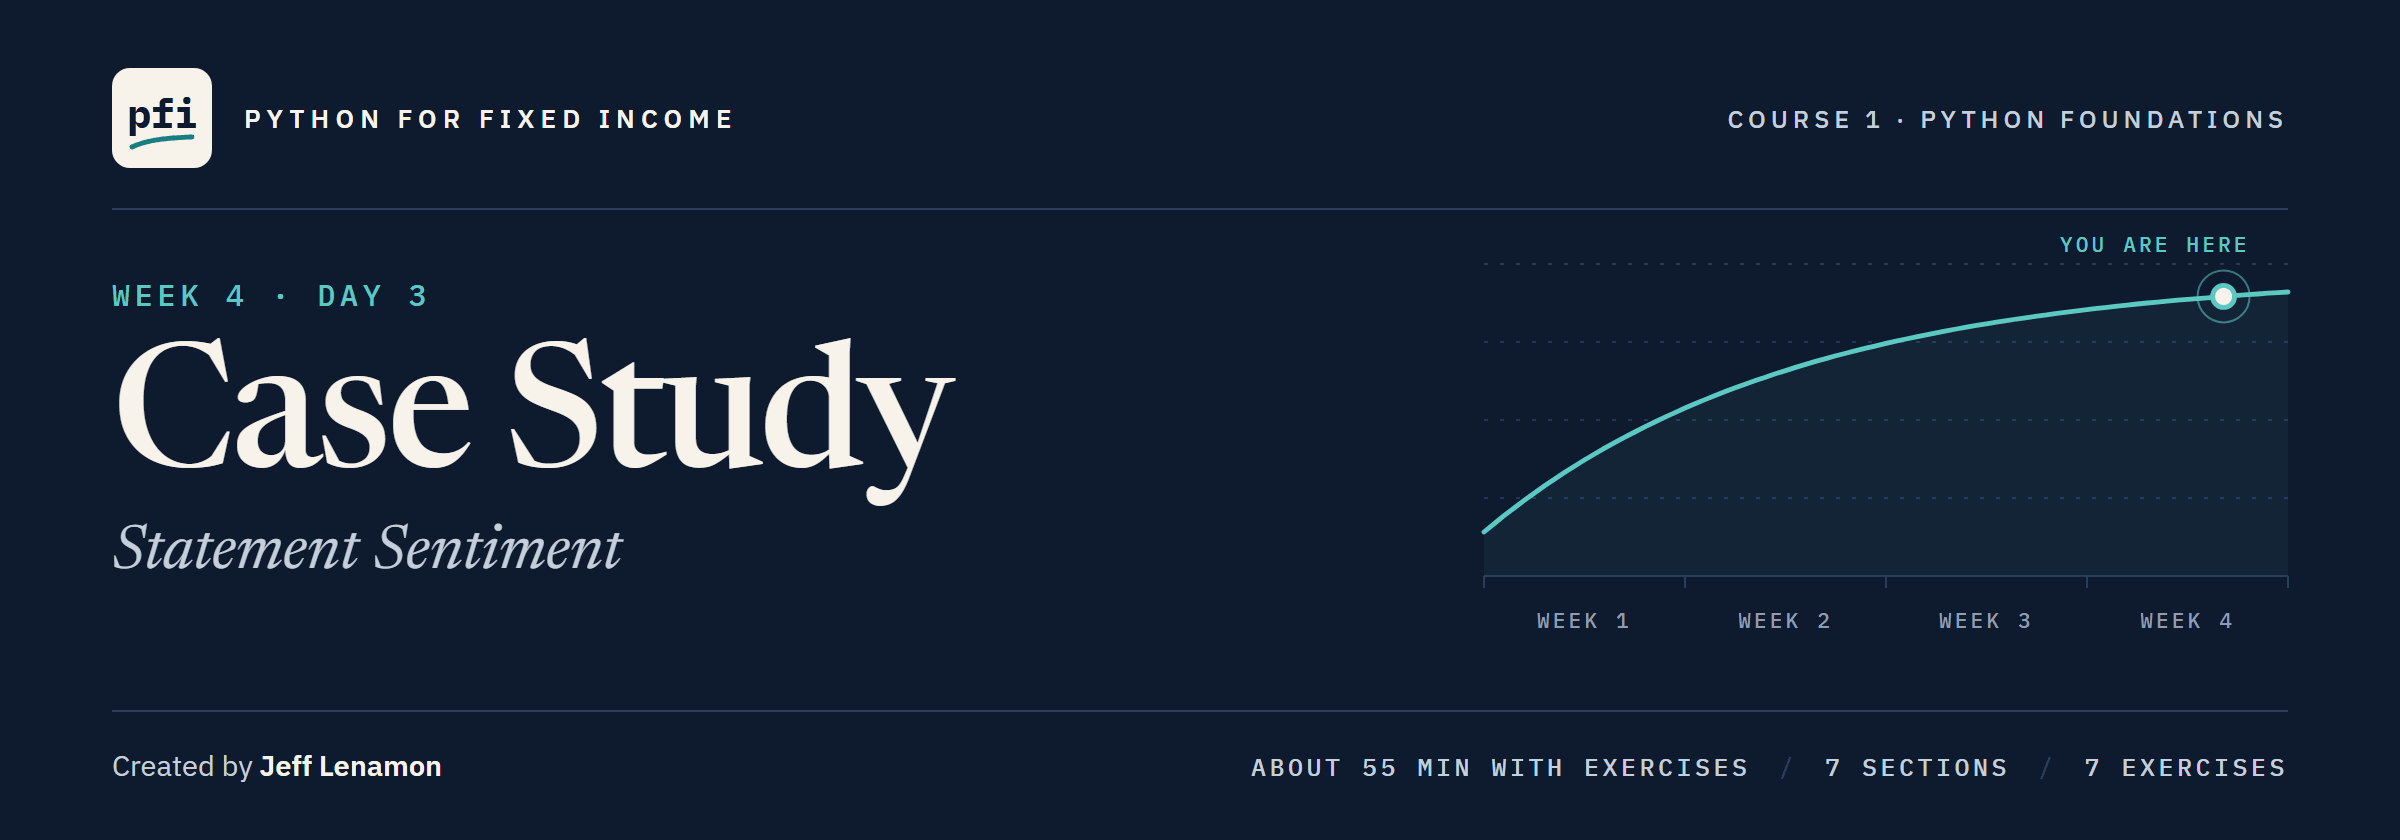

# Case Study: Statement Sentiment

Week 4, Day 3. Three word lists score 46 published statements; the scores meet each other, then yields.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day3/18_case_study_statement_sentiment.ipynb)

## Problem Definition

### Context

The desk lead's twenty-fourth note:

> Analyzing Text Part 2 gave us clean tokens for all 46 FOMC statements. Give me one number per statement for its wording, three ways: two lists we type, a published list, and a list built from the statements' own words. Show me the words behind every number, and whether the three agree. Last: does a change in a score line up with that day's 2 Yr and 10 Yr moves? Describe only: no reading of policy, no view on rates.

### Objective

You are the desk's analyst: answer the note's asks in order.
Report each score as "the list scores the statement of a date at N": a count, never a meaning or a forecast.

### The Data

<table align="left">
<tr><th align="left"></th><th align="left">The statements</th><th align="left">The yields</th></tr>
<tr><td align="left">Source</td><td align="left">Board of Governors of the Federal Reserve System, each statement's press release: https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm</td><td align="left">U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates: https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve</td></tr>
<tr><td align="left">Retrieved</td><td align="left">2026-10-03</td><td align="left">2026-10-03</td></tr>
<tr><td align="left">Span</td><td align="left">46, 2021-01-27 to 2026-09-16; white space tidied only</td><td align="left">2015-01-02 to 2026-10-02, in percent</td></tr>
<tr><td align="left">Reuse</td><td align="left">"Unless otherwise indicated, information on Board's website is in the public domain and may be copied and distributed without permission. Please cite to the Board as the source of the information." https://www.federalreserve.gov/disclaimer.htm</td><td align="left">A U.S. Government work, listed as CC0 1.0 public domain in https://www.treasury.gov/jsonfiles/data.json</td></tr>
</table>
<br clear="left">

### How We Will Work

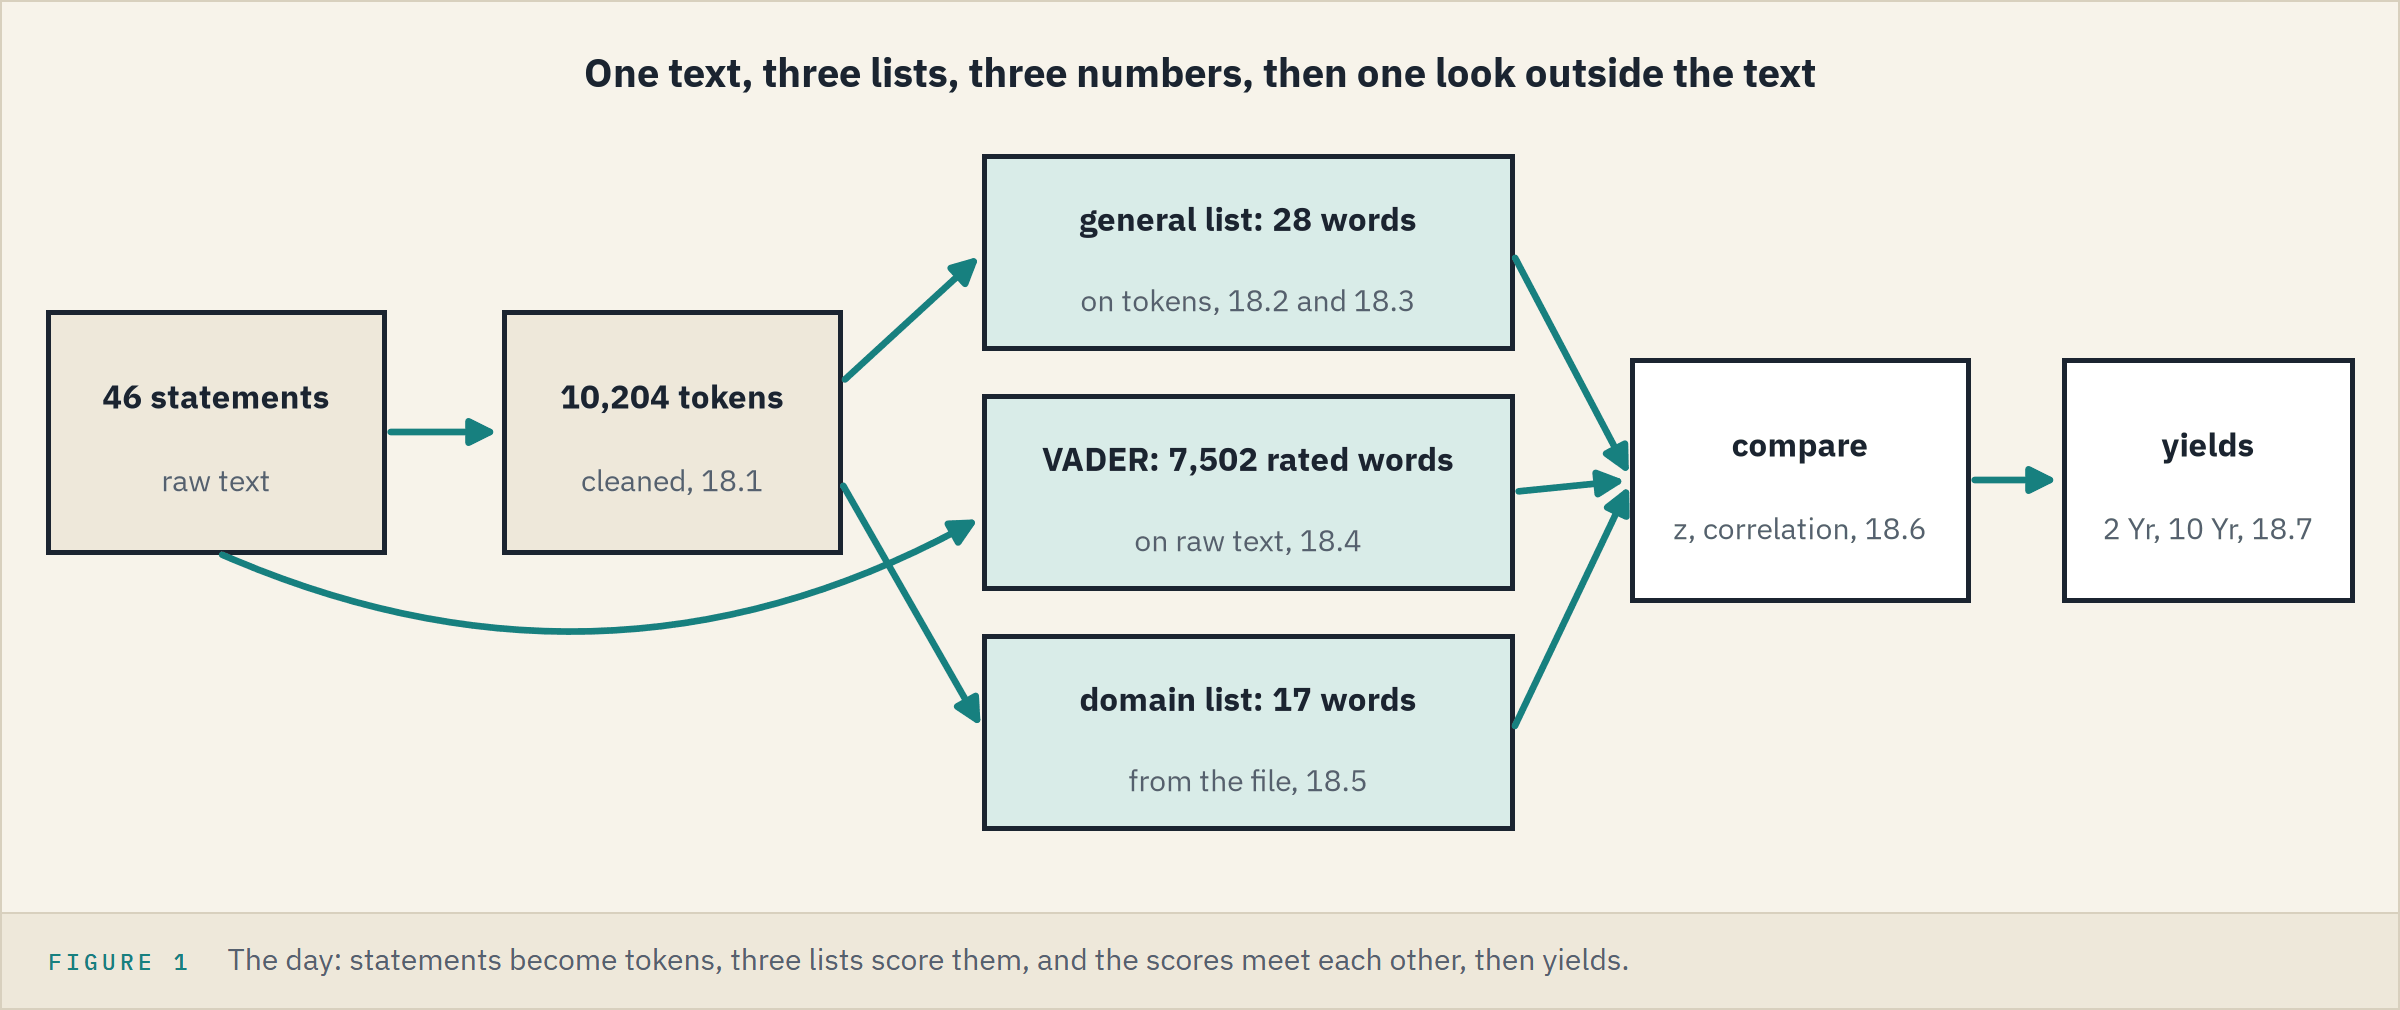

**Every number is printed beside the words that made it.**

## Your Route Through Day 3

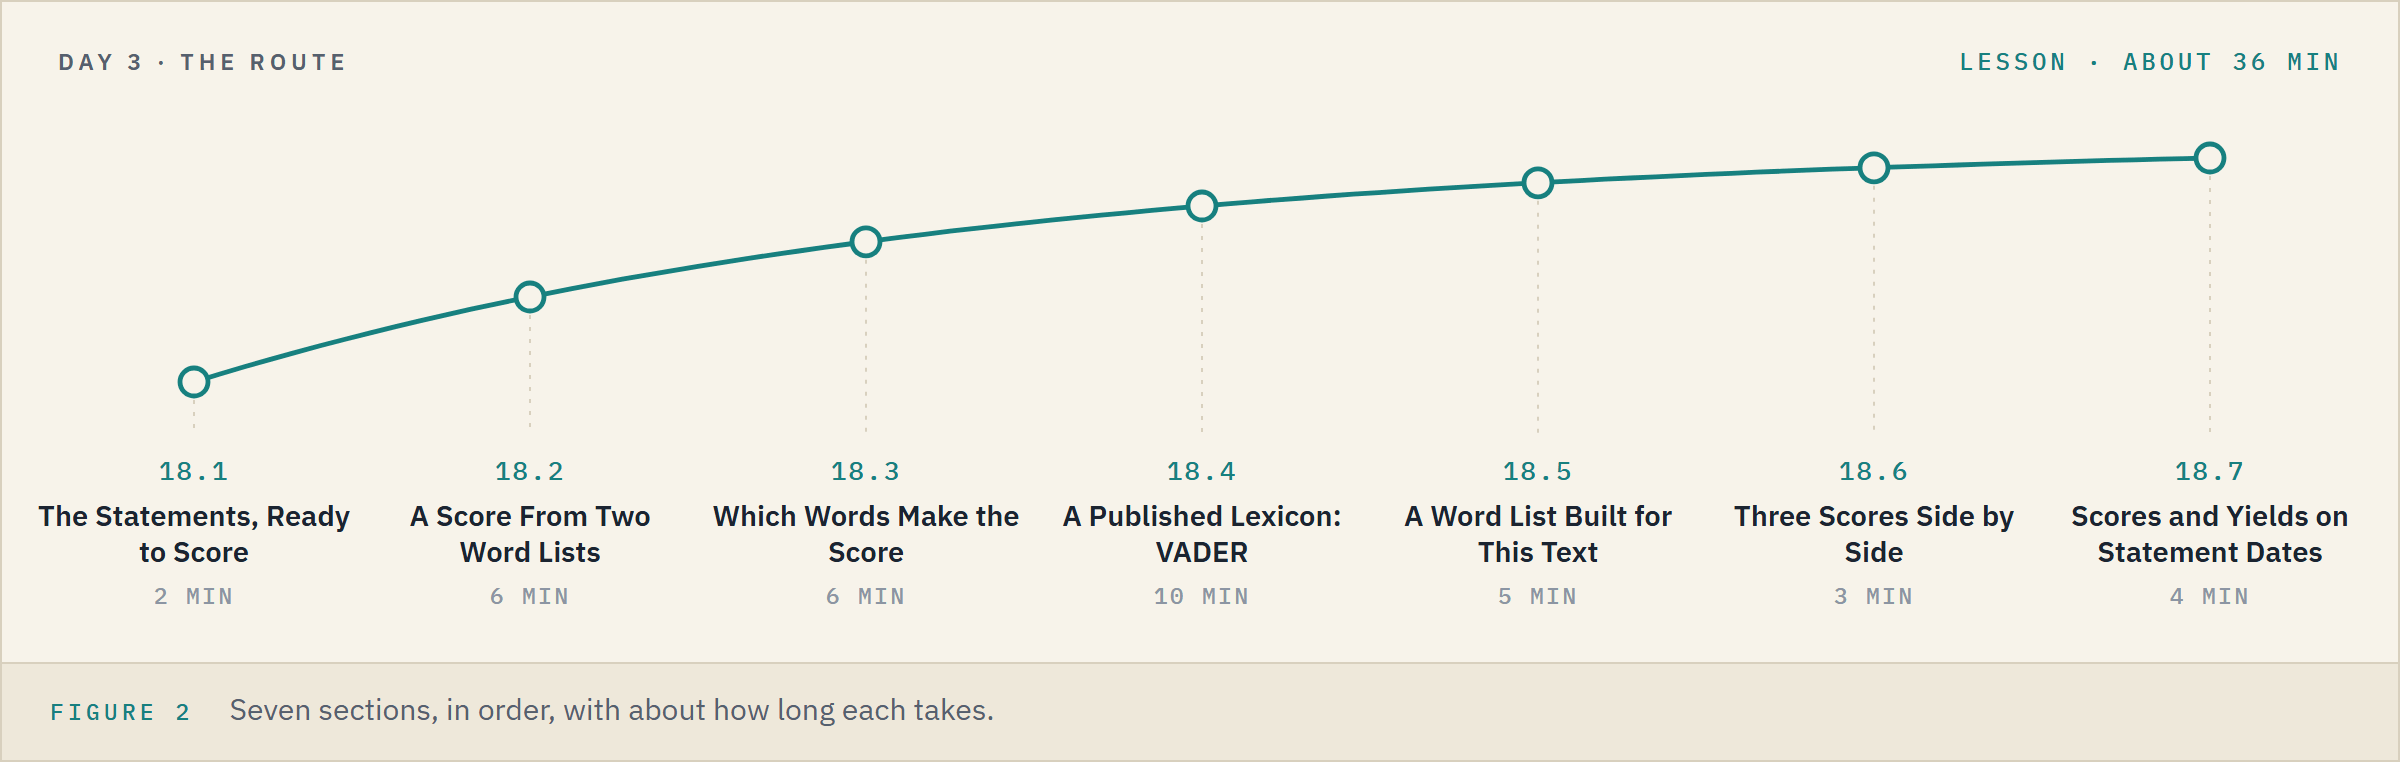

**Time.** About 36 minutes for the lesson, then about 21 for the seven exercises.

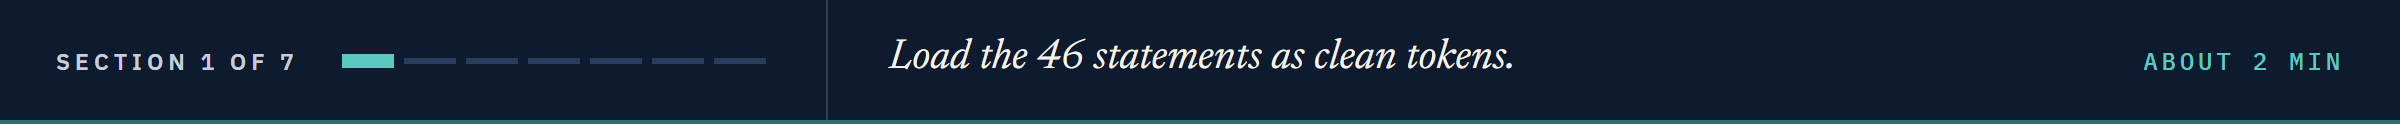

## 18.1 The Statements, Ready to Score

A **lexicon** is a word list; a lexicon score counts its words in a text.

### Load and Check

Q. Load the statements. Is anything missing or in twice?

In [1]:
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns

# the house greens and greys, as in the Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the repo's data folder on your machine; in Colab, GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
# real dates for the charts and the join to yields, as in Combining Part 2
statements['meeting'] = pd.to_datetime(statements['date'], format='%Y-%m-%d')
print(statements.shape, statements.isna().sum().sum(), statements.duplicated().sum())

(46, 4) 0 0


The 46 rows have no gaps and no repeats.

### Yesterday's Cleaning in One Cell

Q. Clean every statement and drop the stopwords, as in Analyzing Text Part 2. How many tokens are kept?

In [2]:
# Analyzing Text Part 2's cleaning: lower case, letters only, one space, then tokens
def clean(text):
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return re.sub(r'\s+', ' ', text).strip().split(' ')

nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
stop_words = stopwords.words('english')

def remove_stop_words(tokens):
    return [token for token in tokens if token not in stop_words]

# no stemming today: a listed word must match as it is spelled
statements['kept'] = statements['text'].apply(clean).apply(remove_stop_words)
statements['n_kept'] = statements['kept'].str.len()
print(statements['n_kept'].sum(), statements['n_kept'].median(), statements['n_kept'].max())
print(statements.nsmallest(4, 'n_kept')[['date', 'n_kept']])

10204 214.0 372
          date  n_kept
45  2026-09-16      79
43  2026-06-17      80
44  2026-07-29     101
40  2026-01-28     178


10,204 tokens are kept, Analyzing Text Part 2's count.

**The three shortest, 79 to 101 tokens, are the last three statements. Keep that in mind.**

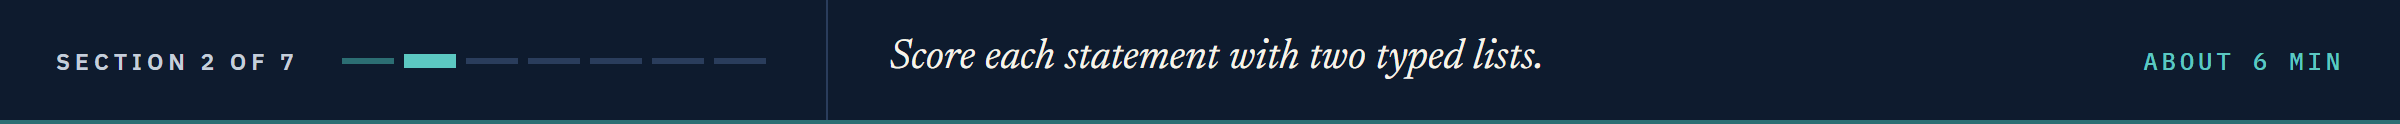

## 18.2 A Score From Two Word Lists

### Two Lists and One Statement

Q. Type a positive and a negative list. Which tokens of the first statement hit each?

In [3]:
# everyday good-news and bad-news words, typed by hand
positive_words = ['good', 'strong', 'better', 'gains', 'support', 'progress', 'improved',
                  'improvement', 'confidence', 'growth', 'solid', 'stable',
                  'recovery', 'benefit']
negative_words = ['bad', 'weak', 'worse', 'risks', 'inflation', 'unemployment', 'pressures',
                  'restrictive', 'uncertain', 'hardship', 'decline', 'loss', 'debt', 'lower']
# the first statement's tokens that are on each list
first_tokens = statements['kept'].iloc[0]
positive_hits = [token for token in first_tokens if token in positive_words]
negative_hits = [token for token in first_tokens if token in negative_words]
print(statements['date'].iloc[0], len(first_tokens), positive_hits)
print(negative_hits)

2021-01-27 304 ['support', 'recovery', 'support', 'progress', 'progress']
['hardship', 'inflation', 'inflation', 'risks', 'inflation', 'inflation', 'inflation', 'inflation', 'inflation', 'inflation', 'risks', 'inflation', 'pressures', 'inflation']


The statement of 2021-01-27 has 5 positive hits and 14 negative, 10 of them `inflation`.

**Print the words that hit.**

### Positives Less Negatives

Q. The score is positives less negatives. Subtract.

In [4]:
# positives less negatives
positive_hits - negative_hits

TypeError: unsupported operand type(s) for -: 'list' and 'list'

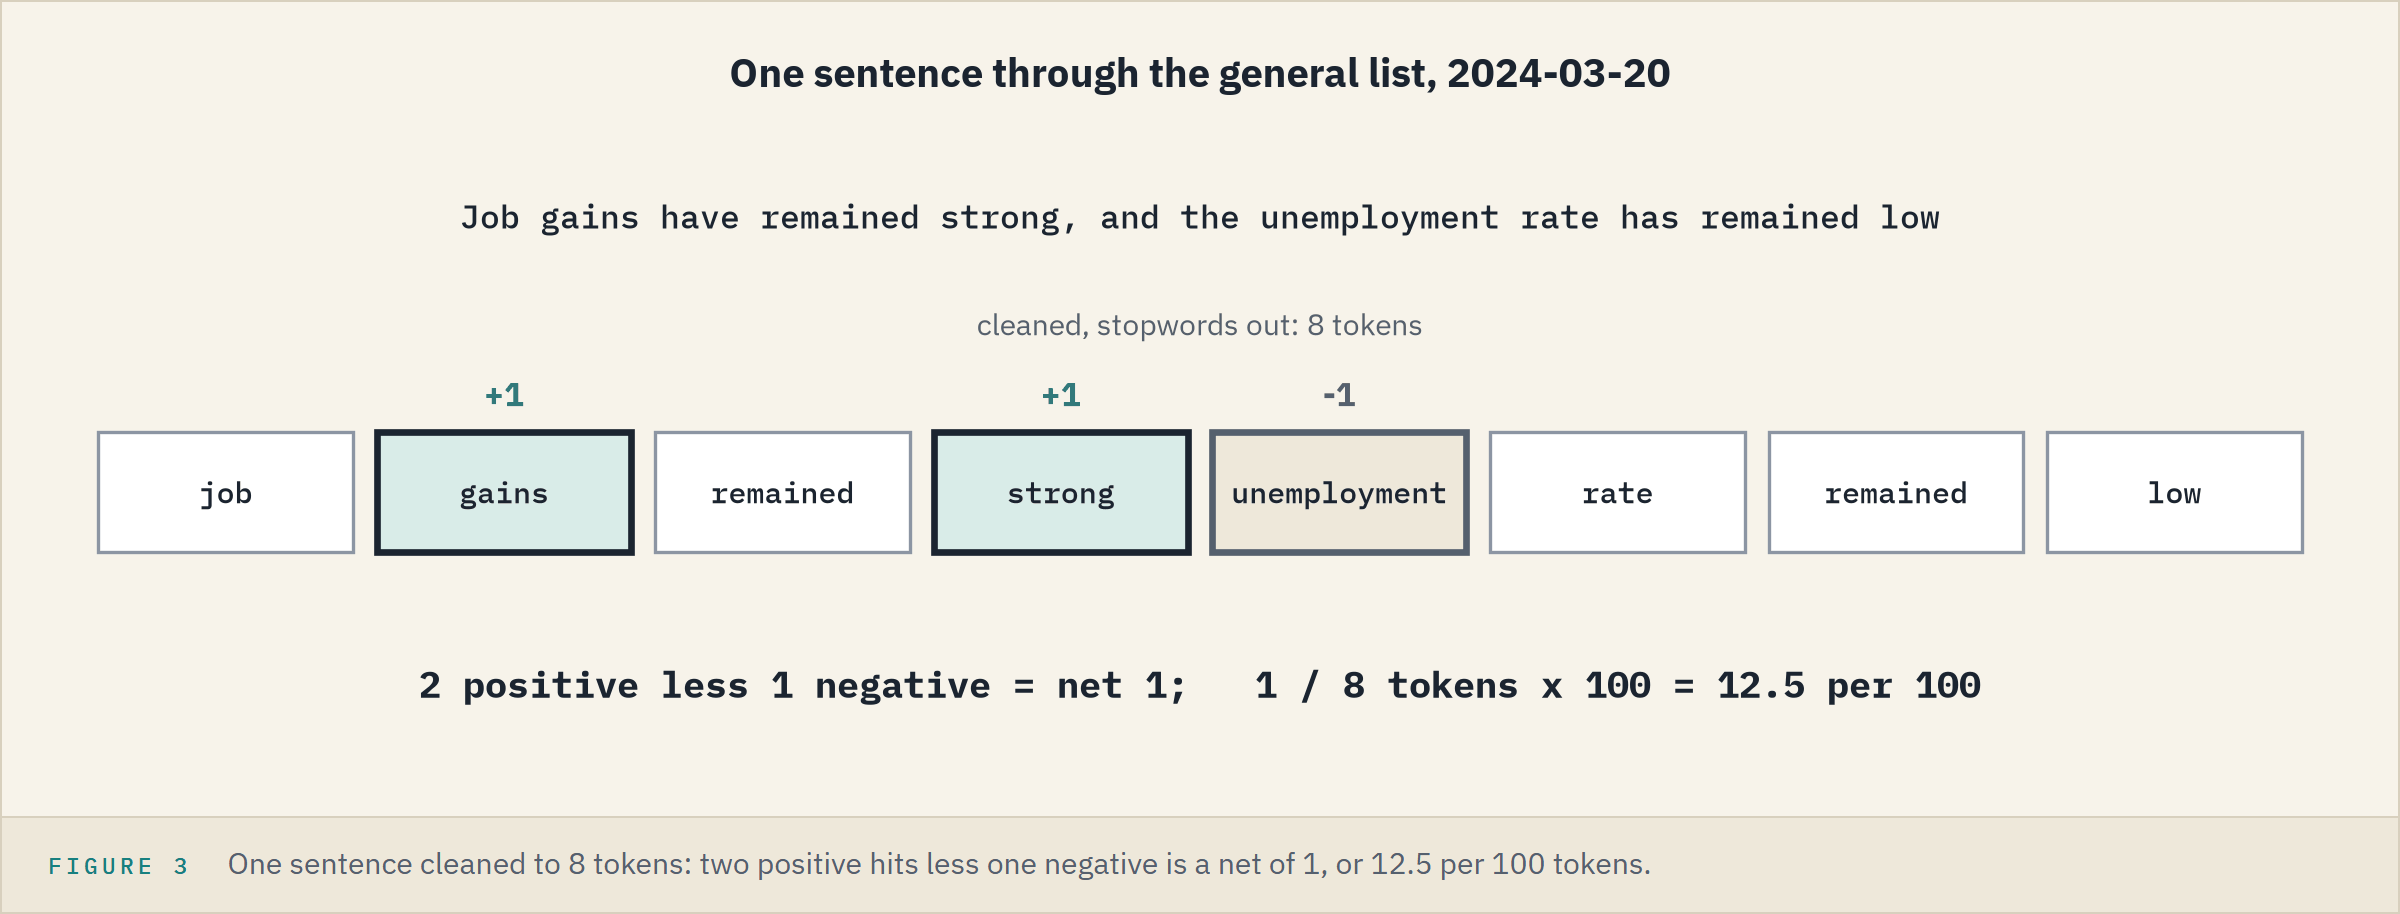

Read the last line, as in week 1's Day 3: one list minus another means nothing.
The score subtracts the two `len()` counts and divides by the tokens, as the picture does for one sentence.

### A Short Statement

**Predict 1**

Q. The statement of 2026-09-16 has a net of 4 hits on 79 tokens; 2021-01-27 has -9 on 304. Which is further from zero, per 100 tokens?

A) 2021-01-27, since 9 hits are more than 4

B) 2026-09-16

C) the same distance

In [5]:
def list_score(tokens, plus_words, minus_words):
    # hits on the plus list less hits on the minus list, per 100 tokens
    plus = len([token for token in tokens if token in plus_words])
    minus = len([token for token in tokens if token in minus_words])
    return (plus - minus) / len(tokens) * 100

def general_score(tokens):
    # the two general lists, fixed
    return list_score(tokens, positive_words, negative_words)

last_tokens = statements['kept'].iloc[-1]
print(round(general_score(last_tokens), 2), round(general_score(first_tokens), 2))
# what one hit is worth, per 100 tokens, on each
print(round(100 / len(last_tokens), 2), round(100 / len(first_tokens), 2))

5.06 -2.96
1.27 0.33


B: 4 on 79 tokens is 5.06 per 100, against -2.96.
One hit moves 79 tokens by 1.27, and 304 tokens by 0.33.

**Keep the count beside every average.**

### Every Statement

Q. Score all 46. Which is lowest, which highest, and how many sit below zero?

In [6]:
# Combining Part 2's apply(): the function on every row
statements['general'] = statements['kept'].apply(general_score)
low, high = statements['general'].idxmin(), statements['general'].idxmax()
print(statements.loc[low, 'date'], round(statements['general'].min(), 2))
print(statements.loc[high, 'date'], round(statements['general'].max(), 2))
print((statements['general'] < 0).sum(), round(statements['general'].mean(), 2))

2024-09-18 -6.51
2026-09-16 5.06
42 -3.88


The general list puts 42 of 46 below zero; its highest is the Predict's short statement.

### The Score Over Time

Q. Draw the general score over time.

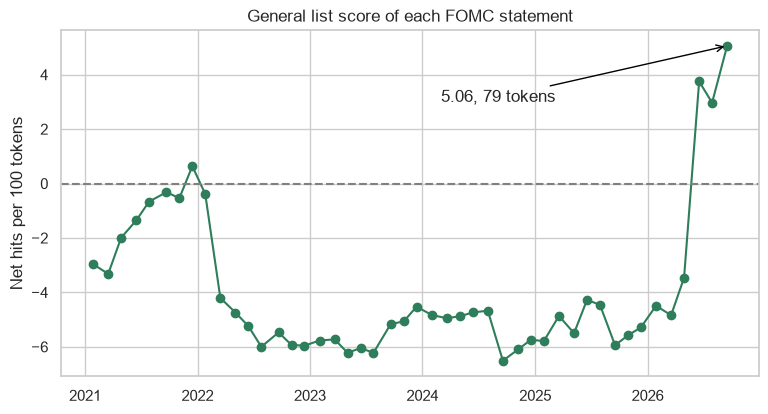

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(statements['meeting'], statements['general'], marker='o')
ax.axhline(0, color='grey', linestyle='--')
# a note on the highest, as in the Visualization notebook
ax.annotate('5.06, 79 tokens', xy=(statements.loc[high, 'meeting'], 5.06),
            xytext=(pd.Timestamp('2024-03-01'), 3),
            arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.set_title('General list score of each FOMC statement')
ax.set_ylabel('Net hits per 100 tokens')
plt.show()

The score drops in early 2022 and jumps at the end, on the three short statements.
The chart shows that it moved, not why.

### Pieces of Text or Whole Tokens

Q. Excel finds a word as a piece of text, as Analyzing Text Part 1's `count()` did. How many hits does that give the first statement?

In [8]:
# count() finds a word anywhere, even inside a longer word
first_text = statements['text'].iloc[0].lower()
print(sum([first_text.count(word) for word in positive_words]))
print(sum([first_text.count(word) for word in negative_words]))
# statements that hold a piece of text
print(statements['text'].str.contains('restrictive').sum())

6
17
4


6 and 17 pieces where the tokens gave 5 and 14: `support` sits inside `supporting`, `weak` inside `weakness` and `weaker`.
A score says which it counts: here, whole tokens.

**Excel side by side.** Text in C2:C47, the positive words in F2:F15; every version.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Statements holding a word</td><td align="left"><code>.str.contains('restrictive')</code></td><td align="left"><code>=COUNTIF(C2:C47, "*restrictive*")</code> returns 4</td></tr>
<tr><td align="left">Pieces of a whole list</td><td align="left">the <code>count()</code> line above</td><td align="left"><code>=SUMPRODUCT((LEN(C2)-LEN(SUBSTITUTE(LOWER(C2),$F$2:$F$15,"")))/LEN($F$2:$F$15))</code> returns 6</td></tr>
</table>
<br clear="left">

**42 of 46 below zero. Before trusting it, look at the words.**

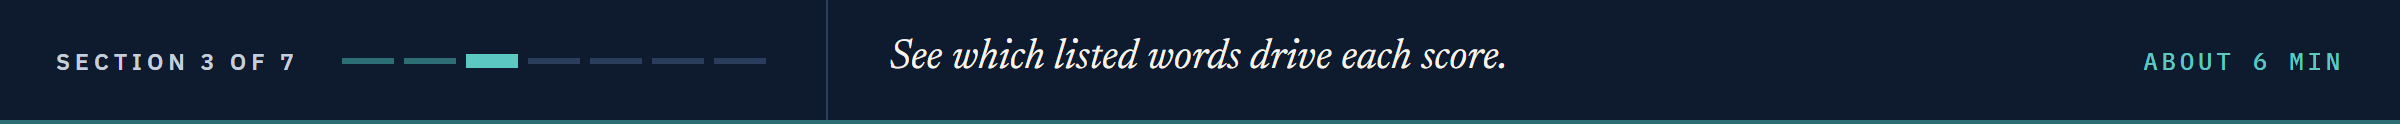

## 18.3 Which Words Make the Score

### Statements Into Sentences

Q. Split every statement into rough sentences, keeping the date.

In [9]:
# Analyzing Text Part 1's split('. ') on every statement, one row per piece
rows = []
for date, text in zip(statements['date'], statements['text']):
    for piece in text.replace('\n', ' ').split('. '):
        rows.append({'date': date, 'sentence': piece})
sentences = pd.DataFrame(rows)
sentences['kept'] = sentences['sentence'].apply(clean).apply(remove_stop_words)
print(len(sentences), (sentences['date'] == '2024-03-20').sum())
print(sentences[sentences['date'] == '2024-03-20']['sentence'].tail(3).tolist())

1198 27
['Kugler; Loretta J', 'Mester; and Christopher J', 'Waller.']


The 1,198 pieces include fragments of names, cut at each middle initial's full stop: a known limit, left in, since a name holds no listed word.

Q. Write two helpers, then find the sentence with `inflation` that repeats most.

In [10]:
def sentences_with(word):
    # the sentences whose kept tokens include the word
    return sentences[sentences['kept'].apply(lambda tokens: word in tokens)]

def show(table, limit):
    # print each sentence with its date
    for date, sentence in zip(table['date'][:limit], table['sentence'][:limit]):
        print(date, '|', sentence)

# how many statements hold each sentence with inflation, most first
repeated = sentences_with('inflation')['sentence'].value_counts()
print(repeated.iloc[0], '|', repeated.index[0])

43 | The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run


That sentence is in 43 of 46 statements and is a negative hit every time.

### One Word's Share

Q. Across all 46, how many hits does each listed word make? Draw them.

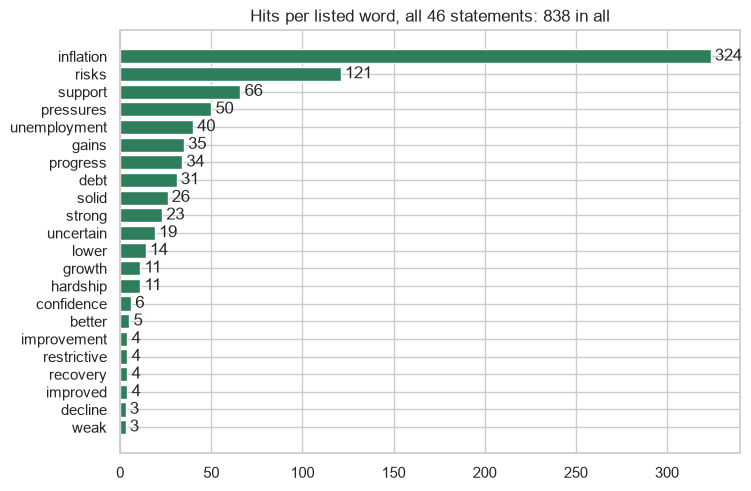

In [11]:
# one Counter for both lists, fed every statement's hits, as in Analyzing Text Part 2
hits = Counter()
for tokens in statements['kept']:
    hits.update([token for token in tokens if token in positive_words + negative_words])
per_word = pd.Series(hits).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(per_word.index, per_word)
ax.bar_label(bars, padding=3)
ax.set_title(f'Hits per listed word, all 46 statements: {per_word.sum()} in all')
plt.show()

`inflation` makes 324 of the 838 hits, more than every positive word together; `good` and `bad` never hit, so they have no bar.

### Terms of the Trade

Q. Print one sentence for each of seven listed words that are plain terms here.

In [12]:
# seven listed words that are terms of the trade in these statements
domain_terms = ['inflation', 'risks', 'restrictive', 'unemployment', 'pressures',
                'strong', 'support']
for word in domain_terms:
    show(sentences_with(word), 1)
seven = sum([hits[word] for word in domain_terms])
print(seven, 'of', sum(hits.values()))

2021-01-27 | Weaker demand and earlier declines in oil prices have been holding down consumer price inflation
2021-01-27 | The ongoing public health crisis continues to weigh on economic activity, employment, and inflation, and poses considerable risks to the economic outlook
2022-11-02 | The Committee anticipates that ongoing increases in the target range will be appropriate in order to attain a stance of monetary policy that is sufficiently restrictive to return inflation to 2 percent over time
2021-12-15 | Job gains have been solid in recent months, and the unemployment rate has declined substantially
2021-01-27 | The Committee's assessments will take into account a wide range of information, including readings on public health, labor market conditions, inflation pressures and inflation expectations, and financial and international developments
2021-04-28 | Amid progress on vaccinations and strong policy support, indicators of economic activity and employment have strengthened
2021-

Seven words that name things here make 628 of the 838 hits.
This is the **domain vocabulary** problem: a general list carries a word's everyday sense.

> STORY: In 2011 Tim Loughran and Bill McDonald counted negative words in 10-K filings with the Harvard Dictionary, a general list: "Almost three-fourths (73.8%) of the negative word counts according to the Harvard list are attributable to words that are typically not negative in a financial context", such as tax, cost and liability. They built finance word lists instead. Source: Journal of Finance 66(1), 35-65, https://doi.org/10.1111/j.1540-6261.2010.01625.x. Their dictionary (https://sraf.nd.edu/loughranmcdonald-master-dictionary/) needs a licence for commercial use, so it stays out of this course.

### Without the Seven

**Predict 2**

Q. Take the seven off both lists and score again. With them, 42 of 46 statements sit below zero. How many now? Write down a number.

In [13]:
# what is left of each list, scored through a lambda, as in Combining Part 2
positive_rest = [word for word in positive_words if word not in domain_terms]
negative_rest = [word for word in negative_words if word not in domain_terms]
general_rest = statements['kept'].apply(
    lambda tokens: list_score(tokens, positive_rest, negative_rest))
print((general_rest < 0).sum(), round(general_rest.mean(), 2))

14 0.51


Only 14 now, and the mean moves from -3.88 to 0.51.

**The text did not change; the list did. A score describes both.**

### A Sentence With `not`

Q. Print every different sentence in the file that holds the word `not`.

In [14]:
# each different sentence once (the EDA notebook's drop_duplicates)
all_not = sentences[sentences['sentence'].str.contains(' not ')].drop_duplicates('sentence')
show(all_not, len(all_not))

2021-07-28 | The sectors most adversely affected by the pandemic have shown improvement but have not fully recovered
2024-01-31 | The Committee does not expect it will be appropriate to reduce the target range until it has gained greater confidence that inflation is moving sustainably toward 2 percent
2025-07-30 | Absent and not voting was Adriana D
2026-04-29 | Logan, who supported maintaining the target range for the federal funds rate but did not support inclusion of an easing bias in the statement at this time.


**Predict 3**

Q. Cleaned and matched against the two lists, how many hits does the 2024-01-31 sentence give?

A) 2: `confidence` and `inflation`

B) 1: `not` cancels `confidence`

C) 0: the sentence describes no change

In [15]:
tokens = all_not['kept'].iloc[1]
print(tokens)
print('not' in stop_words)
print([token for token in tokens if token in positive_words + negative_words])

['committee', 'expect', 'appropriate', 'reduce', 'target', 'range', 'gained', 'greater', 'confidence', 'inflation', 'moving', 'sustainably', 'toward', 'percent']
True
['confidence', 'inflation']


A: `not` is a stopword, gone before any word is matched.
Only four sentences hold `not`, so here little is lost.

**A list sees letters, not meaning. A published list should do better.**

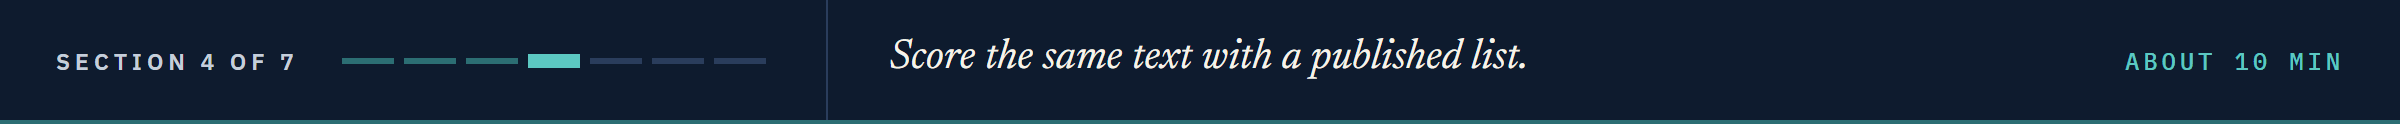

## 18.4 A Published Lexicon: VADER

### Where It Comes From

<table align="left">
<tr><th align="left"></th><th align="left"></th></tr>
<tr><td align="left">Cite as</td><td align="left">Hutto and Gilbert (2014), VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text, nltk's citation (https://www.nltk.org/api/nltk.sentiment.vader.html)</td></tr>
<tr><td align="left">Built for</td><td align="left">"a lexicon and rule-based sentiment analysis tool that is specifically attuned to sentiments expressed in social media" (https://github.com/cjhutto/vaderSentiment)</td></tr>
<tr><td align="left">Ratings, licence</td><td align="left">human raters, -4 to 4; MIT License (same page)</td></tr>
</table>
<br clear="left">

### Looking Up Words

Q. Download the lexicon and look up some words.

In [16]:
# VADER's lexicon is a small download, like the stopwords
nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer
# an object, like the Bond of week 1's Day 4: it holds the lexicon and a scoring method
analyzer = SentimentIntensityAnalyzer()
# .lexicon is a dict, word to rating; get() answers for a missing word, as in week 1's Day 1
print(len(analyzer.lexicon))
look_up = ['good', 'bad', 'strong', 'weak', 'inflation', 'securities', 'treasury']
for word in look_up:
    print(word, analyzer.lexicon.get(word, 'absent'))

7502
good 1.9
bad -2.5
strong 2.3
weak -1.9
inflation absent
securities 1.2
treasury 0.8


Of 7,502 rated words, `inflation` is not one: the word behind 324 hits counts for nothing.
Yet `securities` and `treasury` are rated, names of instruments read as everyday words: the domain problem has moved.

### One Sentence

Q. Score the sentence from the picture in 18.2.

In [17]:
# polarity_scores() returns a dict; compound is its one-number summary, -1 to 1
sentence = sentences[sentences['date'] == '2024-03-20']['sentence'].iloc[1]
print(sentence)
print(analyzer.polarity_scores(sentence))

Job gains have remained strong, and the unemployment rate has remained low
{'neg': 0.267, 'neu': 0.428, 'pos': 0.305, 'compound': 0.1779}


The compound, 0.1779, is "the VADER score" from here on.

### A Whole Statement

**Predict 4**

Q. VADER gave one sentence 0.1779. Score the whole first statement. Write down a number between -1 and 1.

In [18]:
def vader_score(text):
    # the compound of a text
    return analyzer.polarity_scores(text)['compound']

print(vader_score(statements['text'].iloc[0]))

0.9642


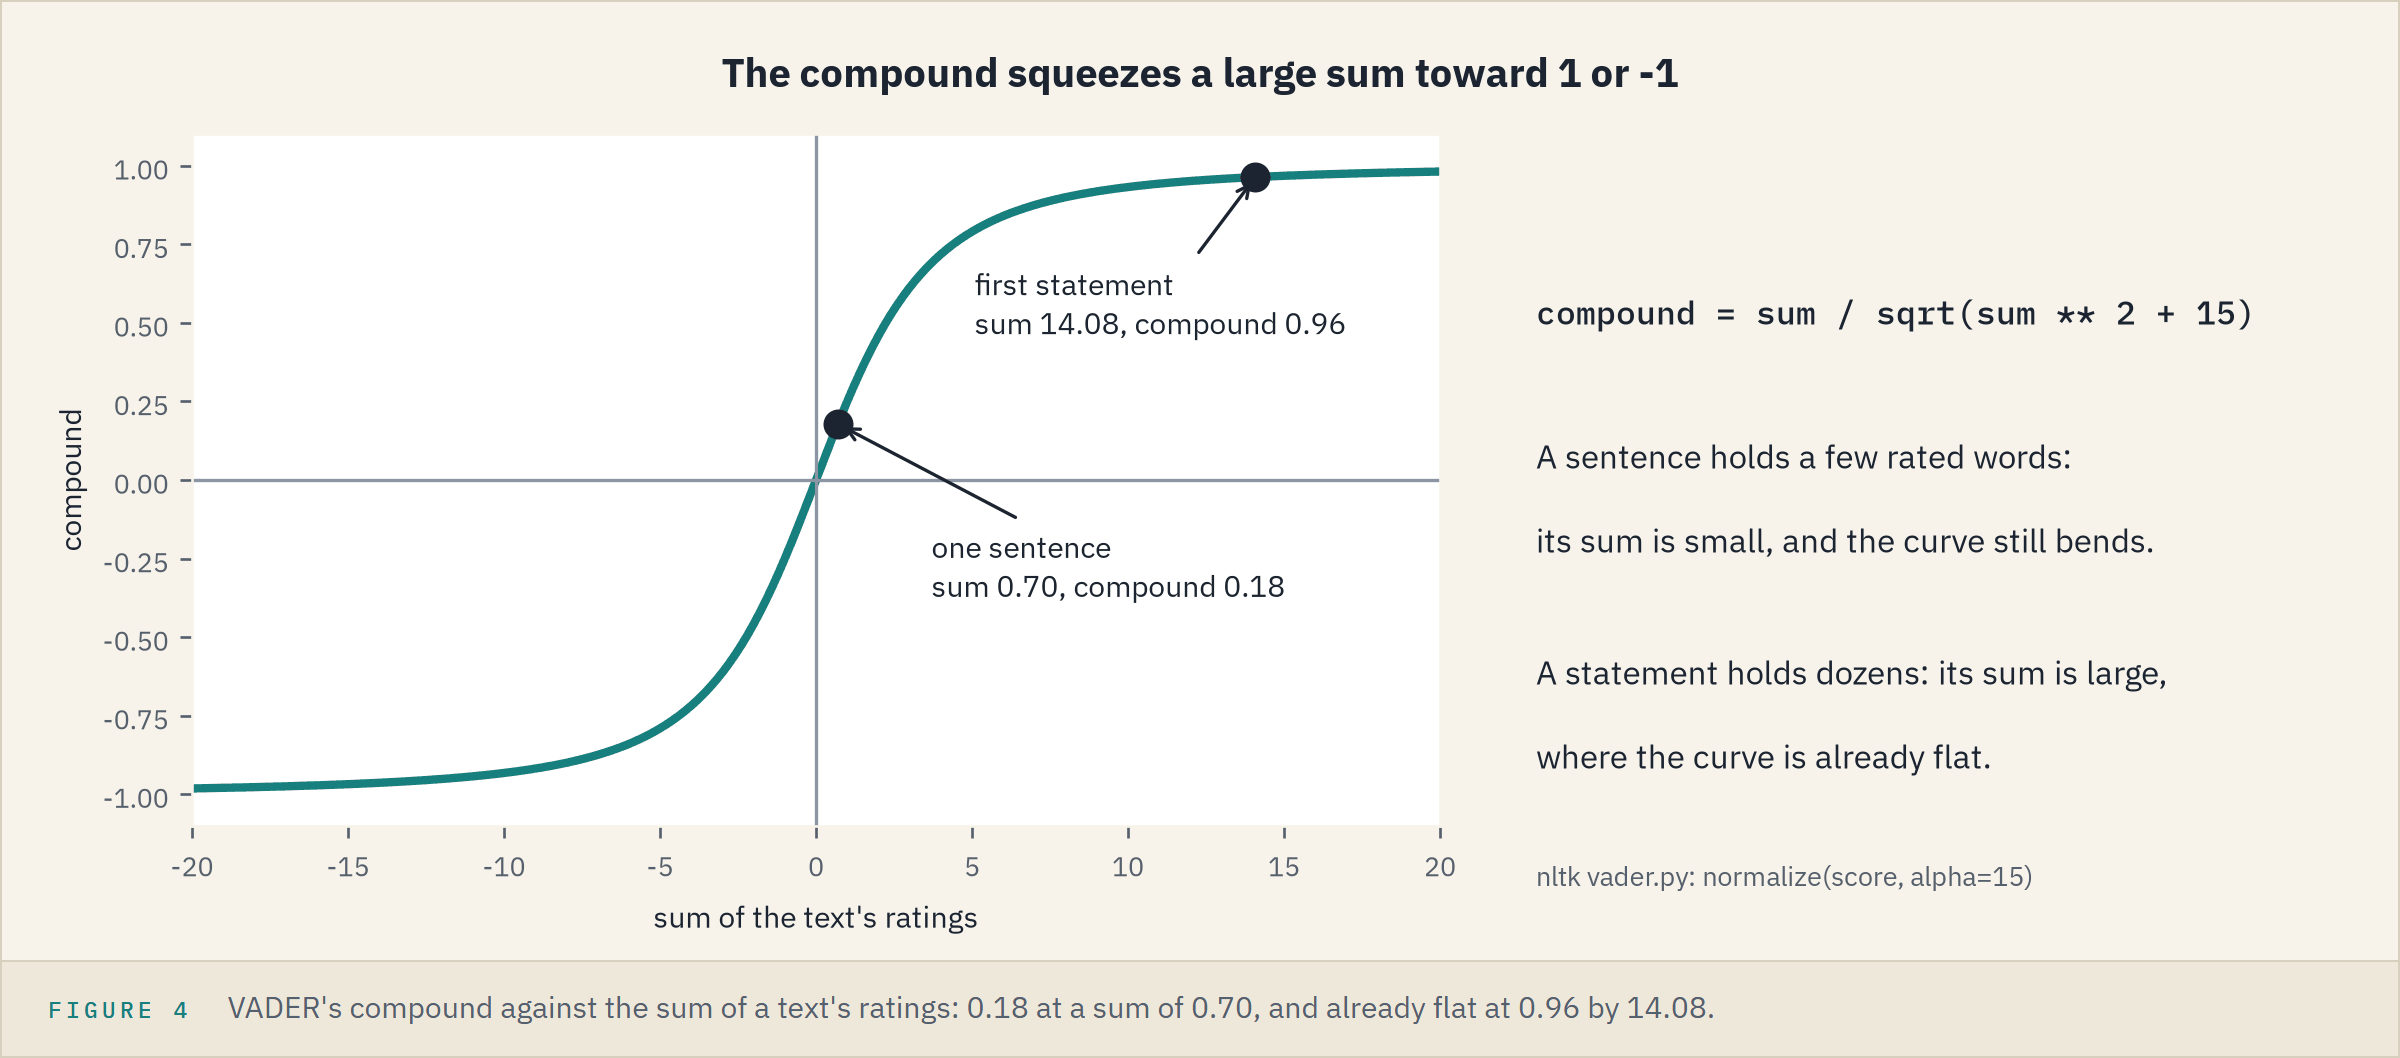

A statement's many rated words make a large sum, and the compound squeezes a large sum toward 1 or -1.

### Raw Text or Cleaned Text

VADER's rules read what cleaning throws away: `not`, `but`, punctuation, capitals.

**Predict 5**

Q. The 2021-07-28 sentence printed in 18.3 scores 0.0037 as published. Score its cleaned tokens, joined by spaces. The new score is:

A) the same: the rated words did not change

B) higher

C) lower

In [19]:
# the same sentence as published, then as cleaned tokens joined by spaces
raw = all_not['sentence'].iloc[0]
cleaned = ' '.join(all_not['kept'].iloc[0])
print(vader_score(raw), vader_score(cleaned))
print('not' in stop_words, 'but' in stop_words)

0.0037 0.1531
True True


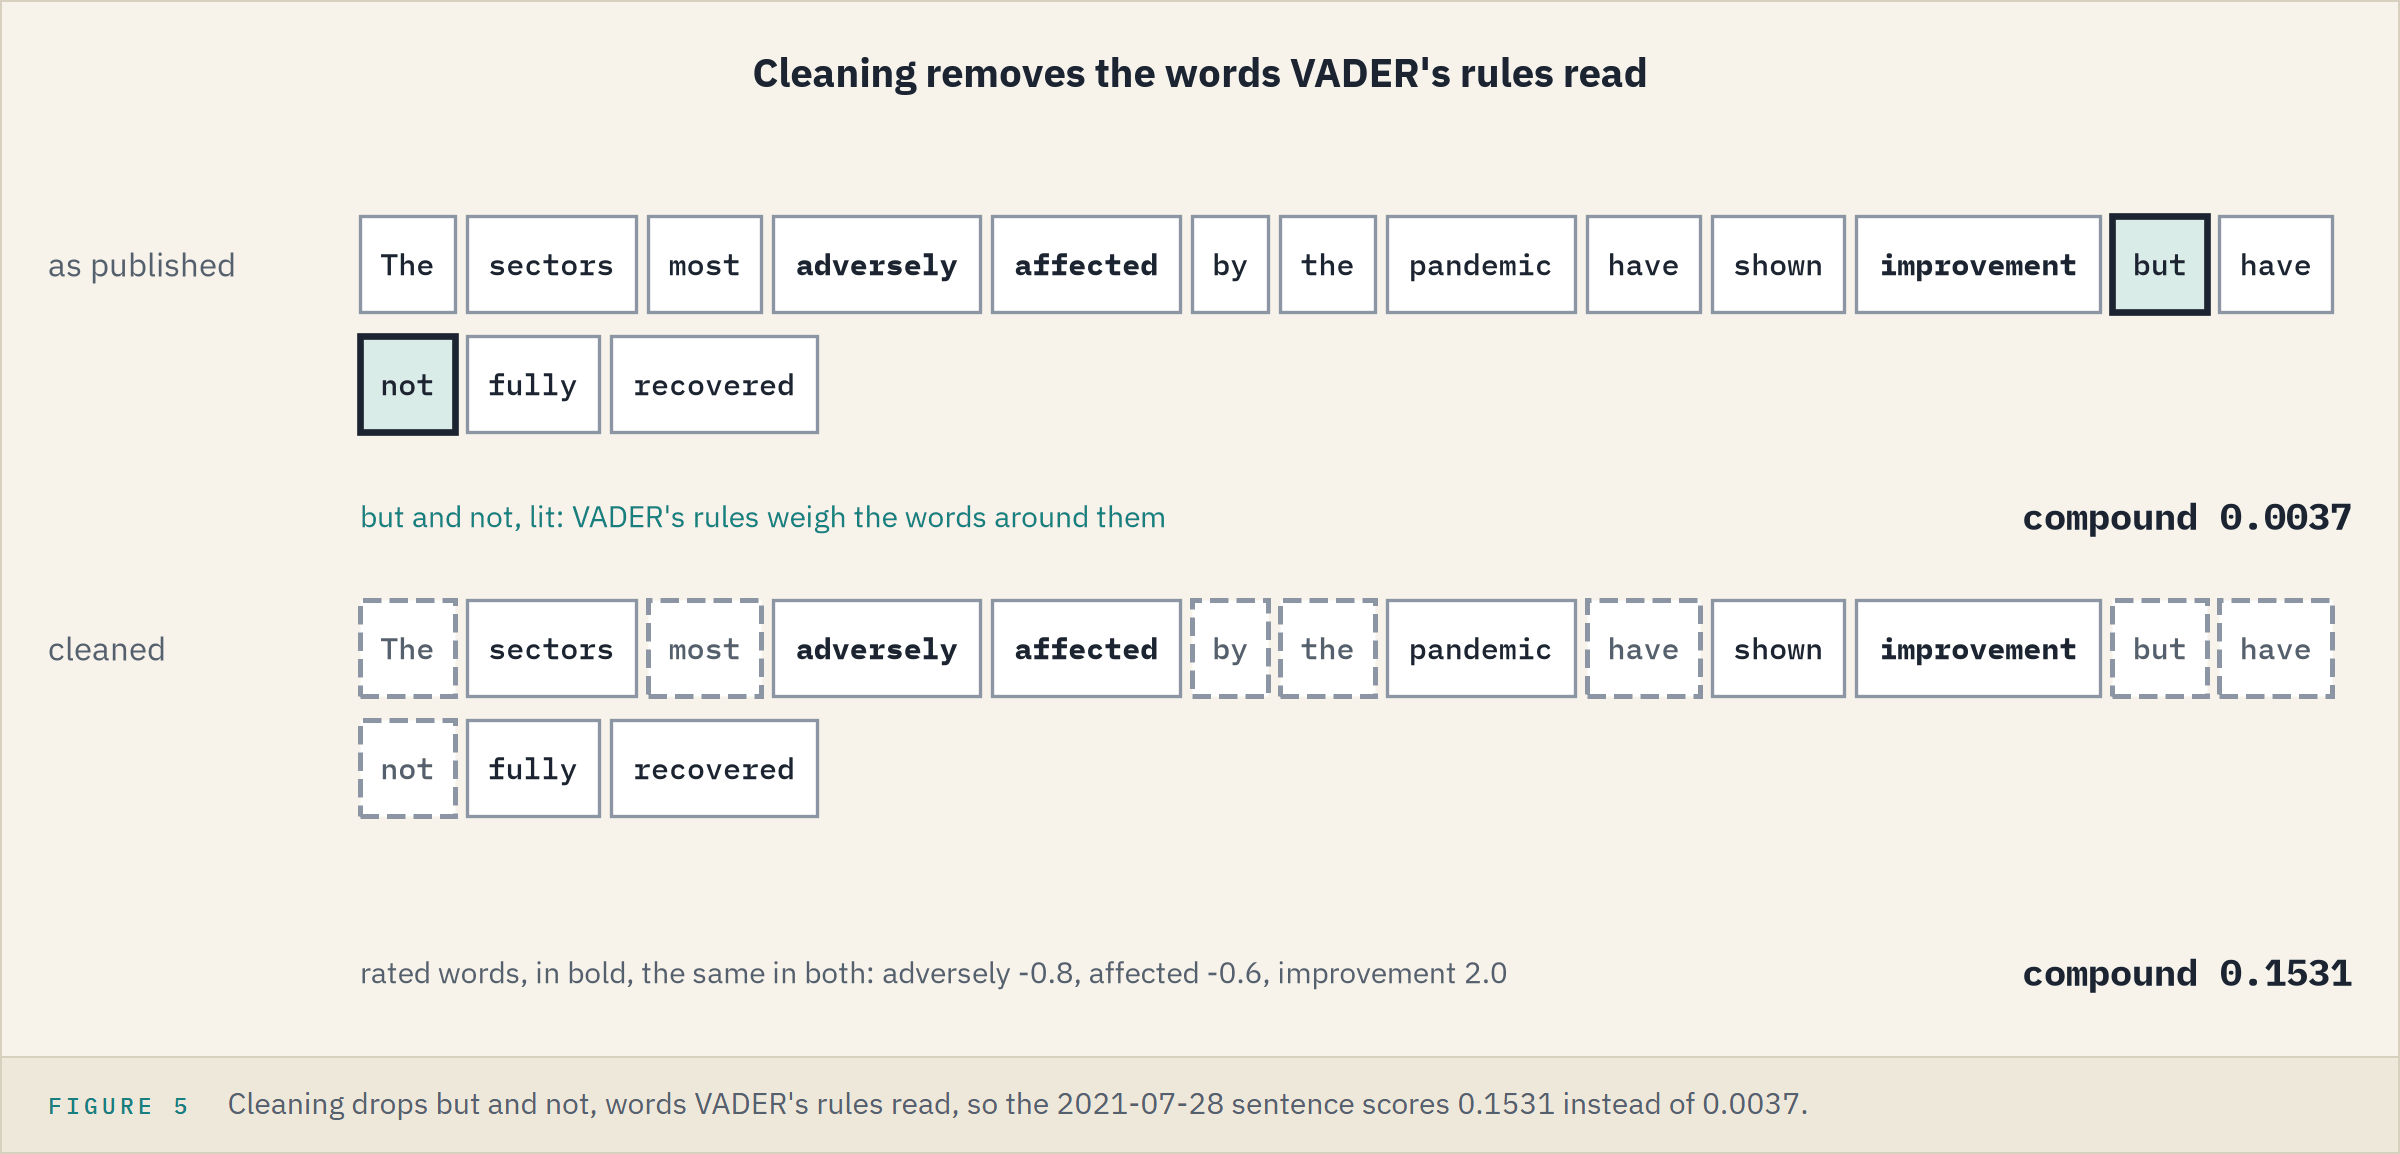

B: 0.1531, because the rules for `not` and `but` had nothing left to read.

**Give each tool the input it was built for.**

Q. Score all 46 both ways. How many change?

In [20]:
statements['vader'] = statements['text'].apply(vader_score)
# .str.join(' ') joins each row's token list; abs() drops the sign of a gap
vader_cleaned = statements['kept'].str.join(' ').apply(vader_score)
gap = (vader_cleaned - statements['vader']).abs()
print((gap > 0).sum(), (gap > 0.1).sum(), round(gap.max(), 2))
print(statements.loc[gap.idxmax(), 'date'], statements.loc[gap.idxmax(), 'vader'])

41 8 0.36
2025-06-18 0.802


41 of 46 change; 2025-06-18 scores 0.802 raw and moves 0.36.

### Every Statement

Q. Draw VADER's score over time.

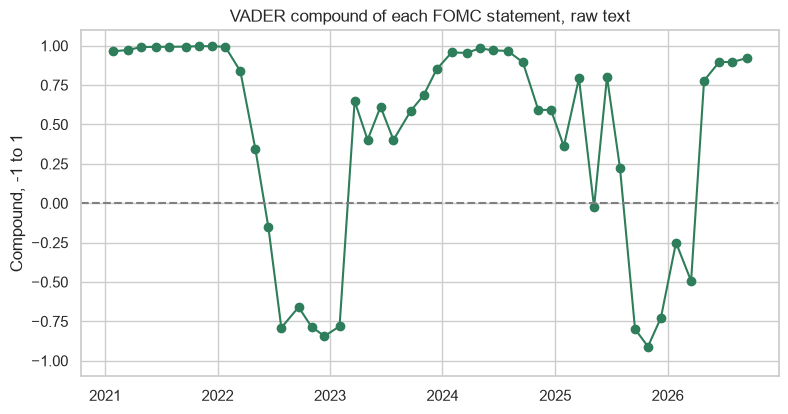

15 12


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(statements['meeting'], statements['vader'], marker='o')
ax.axhline(0, color='grey', linestyle='--')
# the compound cannot leave -1 to 1
ax.set_ylim(-1.1, 1.1)
ax.set_title('VADER compound of each FOMC statement, raw text')
ax.set_ylabel('Compound, -1 to 1')
plt.show()
print((statements['vader'] > 0.9).sum(), (statements['vader'] < 0).sum())

VADER puts 15 statements above 0.9 and 12 below zero, where the general list put 42.

### Which Words VADER Rated

Q. List the rated words of Predict 3's sentence, split as VADER splits it.

In [22]:
# SentiText is the class VADER uses to split a text
from nltk.sentiment.vader import SentiText

def rated_words(text):
    # VADER's own split: SentiText takes the text and two settings VADER keeps in
    # analyzer.constants, its list of punctuation marks and the pattern that removes them;
    # .words_and_emoticons is the list of words it made, punctuation trimmed
    split_text = SentiText(text, analyzer.constants.PUNC_LIST,
                           analyzer.constants.REGEX_REMOVE_PUNCTUATION)
    tokens = [token.lower() for token in split_text.words_and_emoticons]
    return [(token, analyzer.lexicon[token]) for token in tokens if token in analyzer.lexicon]

print(vader_score(all_not['sentence'].iloc[1]), rated_words(all_not['sentence'].iloc[1]))
# backed has a rating, but VADER reads mortgage-backed as one word
print(analyzer.lexicon.get('backed'), rated_words('agency mortgage-backed securities'))

0.8126 [('gained', 1.6), ('greater', 1.5), ('confidence', 2.3)]
0.1 [('securities', 1.2)]


VADER's `not` reaches at most the three words after it, so `gained`, `greater` and `confidence` count in full.
`backed` is rated, yet VADER never scores it inside `mortgage-backed`, while our `clean()` would split it off.

**List the words behind a score as the tool read them.**

### From a Score to a Label

The authors' cut-offs: 0.05 or more is positive, -0.05 or less negative, anything between neutral.

Q. Write the rule and label all 46.

In [23]:
def label_score(compound, cutoff=0.05):
    # a default cut-off, as in week 1's Day 1 Part 2
    if compound >= cutoff:
        return 'positive'
    elif compound <= -cutoff:
        return 'negative'
    return 'neutral'

statements['vader_label'] = statements['vader'].apply(label_score)
# reindex() sets the order and gives 0 to a label that never occurs
label_order = ['negative', 'neutral', 'positive']
print(statements['vader_label'].value_counts().reindex(label_order, fill_value=0))

vader_label
negative    11
neutral      1
positive    34
Name: count, dtype: int64


Q. Draw the labels as shares.

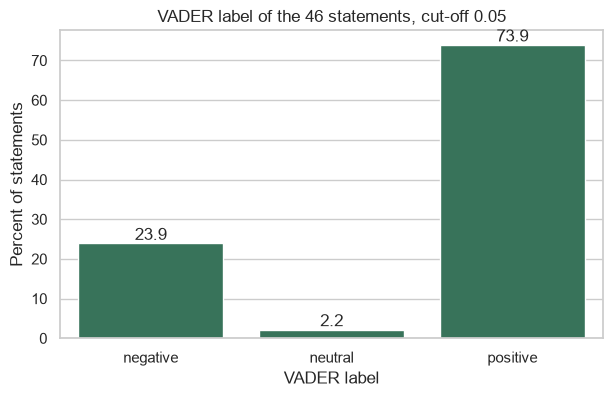

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
# stat='percent' draws each bar as a share of all rows
sns.countplot(data=statements, x='vader_label', order=label_order, stat='percent', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.1f')
ax.set_title('VADER label of the 46 statements, cut-off 0.05')
ax.set_xlabel('VADER label')
ax.set_ylabel('Percent of statements')
plt.show()

One statement is neutral: a long text's compound sits near the ends.

Q. Count the labels at five cut-offs.

In [25]:
# apply() passes cutoff= on to label_score; str() makes each cut-off a row label
rows = {}
for cutoff in [0.05, 0.25, 0.5, 0.75, 0.9]:
    labels = statements['vader'].apply(label_score, cutoff=cutoff)
    rows[str(cutoff)] = labels.value_counts().reindex(label_order, fill_value=0)
pd.DataFrame(rows).T.style.background_gradient(cmap='Greens', axis=None)

vader,negative,neutral,positive
0.05,11,1,34
0.25,10,3,33
0.5,8,9,29
0.75,6,17,23
0.9,1,30,15


Neutral climbs from 1 to 30 and positive falls from 34 to 15; the scores never changed.

**Excel side by side.** The lexicon on a sheet `lexicon` (words in A, ratings in B), VADER's scores in E2:E47.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Look up a rating</td><td align="left"><code>.lexicon.get('strong', 0)</code></td><td align="left"><code>=XLOOKUP("strong", lexicon!A:A, lexicon!B:B, 0)</code> returns 2.3, and 0 for a missing word</td></tr>
<tr><td align="left">The label</td><td align="left"><code>label_score(compound)</code></td><td align="left"><code>=IF(E2&gt;=$H$1,"positive",IF(E2&lt;=-$H$1,"negative","neutral"))</code>, the cut-off in H1</td></tr>
<tr><td align="left">Labels at a cut-off</td><td align="left"><code>value_counts()</code></td><td align="left"><code>=COUNTIF($E$2:$E$47,"&gt;="&amp;H2)</code> and <code>"&lt;="&amp;-H2</code> return 29 and 8 at 0.5</td></tr>
</table>
<br clear="left">

`XLOOKUP` is in Microsoft 365 and Excel 2021 on.

**The cut-off moves the counts as much as the text does. A list built for this text is next.**

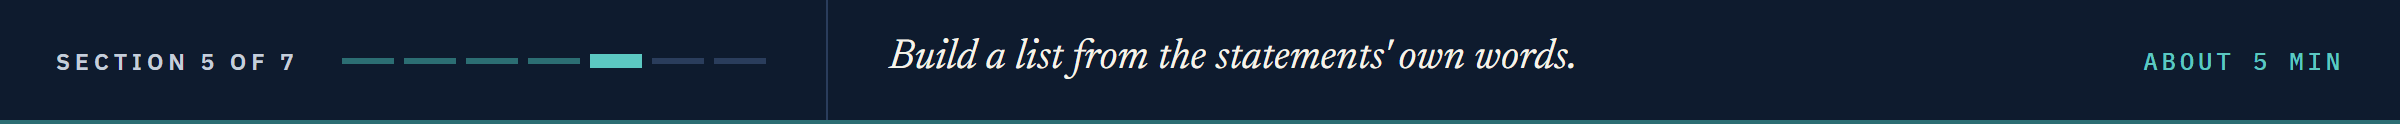

## 18.5 A Word List Built for This Text

### Candidates From the File

Two groups, defined by what the words say: **firm** (activity rising or solid) and **soft** (falling or weak).

Q. Count every token in the file, and fix the two groups from words it uses.

In [26]:
# every kept token, counted, as in Analyzing Text Part 2; a Counter gives 0 for a word it never saw
all_counts = Counter()
for tokens in statements['kept']:
    all_counts.update(tokens)
print(len(all_counts), [all_counts[word] for word in ['booming', 'contracted', 'slumped']])
# typed after reading all_counts.most_common()
firm_words = ['expanding', 'expand', 'expanded', 'solid', 'strong', 'robust', 'strengthened',
              'picked', 'resilient', 'gains']
soft_words = ['slowed', 'moderated', 'declined', 'weak', 'weakness', 'weaker', 'softened']
print(sum([all_counts[word] for word in firm_words]))
print(sum([all_counts[word] for word in soft_words]))

507 [0, 0, 0]
133
26


Of 507 different tokens, the firm words hit 133 times and the soft 26; `booming`, `contracted` and `slumped` never appear.
It is one teaching list among many, printed in full.

### The Domain Score

Q. Score every statement: firm less soft, per 100 tokens.

In [27]:
def domain_score(tokens):
    # the list built for this text
    return list_score(tokens, firm_words, soft_words)

statements['domain'] = statements['kept'].apply(domain_score)
print(round(statements['domain'].mean(), 2), (statements['domain'] < 0).sum())
print(statements['domain'].round(2).tolist()[-4:], statements['n_kept'].tolist()[-4:])

1.3 3
[1.49, 5.0, 3.96, 7.59] [202, 80, 101, 79]


Only 3 statements fall below zero.

Q. Draw it.

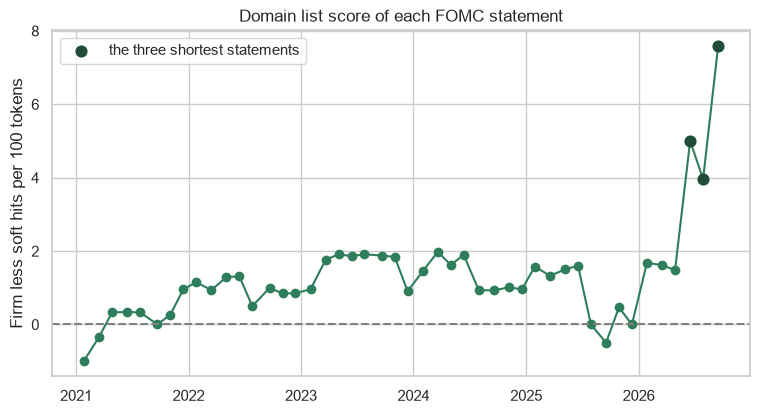

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(statements['meeting'], statements['domain'], marker='o')
ax.axhline(0, color='grey', linestyle='--')
# the three short statements again, on top (zorder=3), in the dark green
ax.scatter(statements['meeting'].iloc[-3:], statements['domain'].iloc[-3:],
           s=60, color='#1E4D3A', zorder=3, label='the three shortest statements')
ax.legend()
ax.set_title('Domain list score of each FOMC statement')
ax.set_ylabel('Firm less soft hits per 100 tokens')
plt.show()

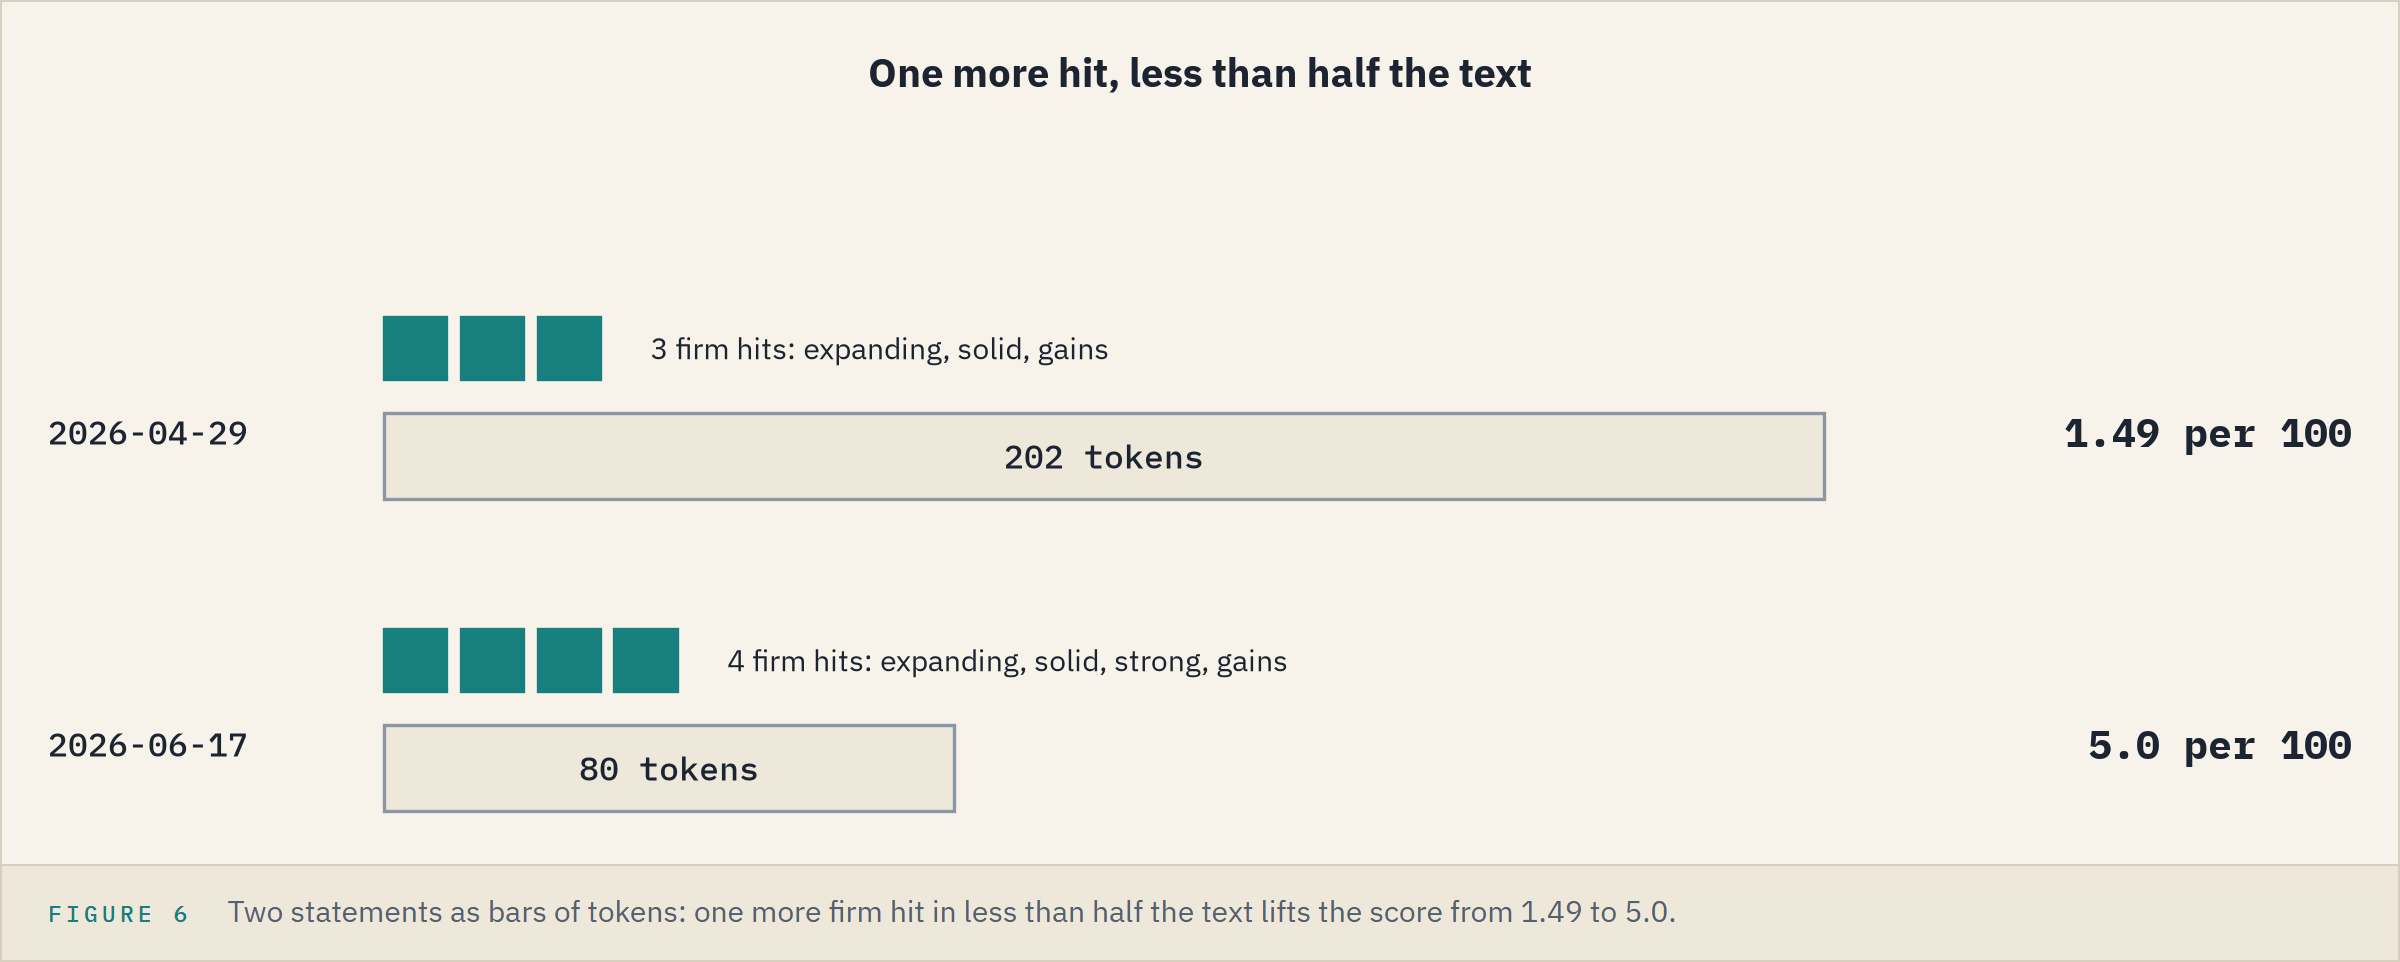

The last three jump to 5.0, 3.96 and 7.59, mostly through the denominator.

### What `declined` Describes

Q. Print every different sentence with the soft word `declined`.

In [29]:
show(sentences_with('declined').drop_duplicates('sentence'), 5)

2021-12-15 | Job gains have been solid in recent months, and the unemployment rate has declined substantially
2022-03-16 | Job gains have been strong in recent months, and the unemployment rate has declined substantially
2022-05-04 | Job gains have been robust in recent months, and the unemployment rate has declined substantially
2025-12-10 | The Committee judges that reserve balances have declined to ample levels and will initiate purchases of shorter-term Treasury securities as needed to maintain an ample supply of reserves on an ongoing basis


In none of the four does `declined` describe activity: three are about the unemployment rate, one about reserve balances.

### `gains` Beside `slowed`

**Predict 6**

Q. One sentence of 2024-09-18 holds `gains` and `slowed` and no other domain word. What does it add to the statement's net hits?

A) -1

B) 0

C) +1

In [30]:
# the sentences holding gains, then those that also hold slowed, then the one of 2024-09-18
both = sentences_with('gains')
both = both[both['kept'].apply(lambda tokens: 'slowed' in tokens)]
one = both[both['date'] == '2024-09-18']
show(one, 1)
print([token for token in one['kept'].iloc[0] if token in firm_words + soft_words])

2024-09-18 | Job gains have slowed, and the unemployment rate has moved up but remains low
['gains', 'slowed']


B: one firm hit and one soft hit cancel to 0.

**Excel side by side.** Firm words in J2:J11, soft in K2:K8: 18.2's `SUMPRODUCT` on each, firm less soft.
Pieces bite harder here: `expanding` counts twice, as itself and as `expand`, and `against` holds `gains`.

**Built from the file, the list is still blind to which word describes which.**

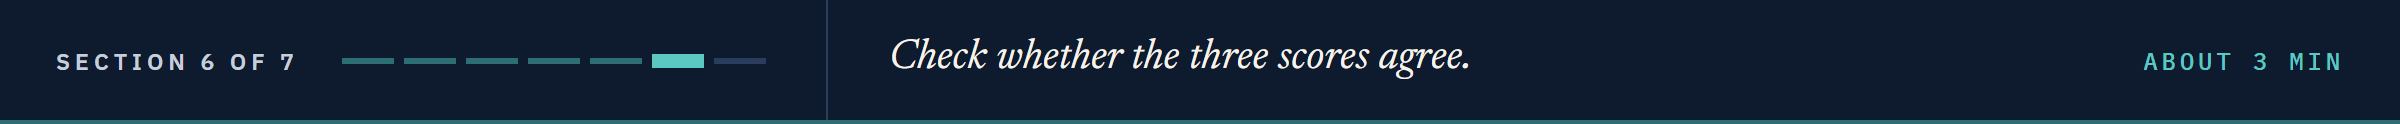

## 18.6 Three Scores Side by Side

### One Table

Q. Put the three scores in one table. How closely do they move together?

In [31]:
# dates as row labels, as in pandas Part 1
scores = statements.set_index('meeting')[['general', 'vader', 'domain']]
# corr(), as in the Visualization notebook: 1 would mean they rise and fall exactly together
scores.corr().style.format('{:.2f}').background_gradient(cmap='Greens', vmin=-1, vmax=1)

,general,vader,domain
general,1.00,0.48,0.51
vader,0.48,1.00,0.21
domain,0.51,0.21,1.00


The pairs correlate at 0.48, 0.51 and 0.21: three lists read the same texts and agree loosely.

### One Scale

Q. Put the three on one scale with z-scores, and draw them.

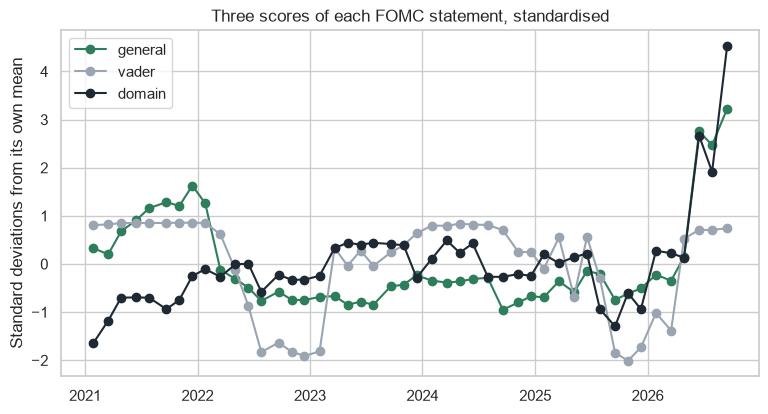

[0.33, 0.81, -1.65]


In [32]:
# z-scores, as in the EDA notebook: each column from its own mean, in standard deviations
z = (scores - scores.mean()) / scores.std()
fig, ax = plt.subplots(figsize=(9, 4.5))
for column, colour in [('general', '#2E7D5B'), ('vader', '#9AA5B1'), ('domain', '#1F2933')]:
    ax.plot(z.index, z[column], marker='o', color=colour, label=column)
ax.legend()
ax.set_title('Three scores of each FOMC statement, standardised')
ax.set_ylabel('Standard deviations from its own mean')
plt.show()
print(z.iloc[0].round(2).tolist())

The lines do not track: the first statement sits above its mean on two lists and 1.65 below on the third.

### Change From the Statement Before

Q. Take each score's change from the statement before. Do the three agree on the changes?

In [33]:
# diff(), as in the Treasury case study: each row less the row above; the first has none
changes = scores.diff()
print(changes.corr().round(2))
# did general and domain move the same way? iloc[1:] skips the first row
same_way = (changes['general'] > 0) == (changes['domain'] > 0)
print(same_way.iloc[1:].sum(), 'of', len(changes) - 1)

         general  vader  domain
general     1.00   0.33    0.62
vader       0.33   1.00    0.20
domain      0.62   0.20    1.00
21 of 45


The changes correlate at 0.33, 0.62 and 0.20, yet general and domain moved the same way only 21 times in 45.
A few large changes can lift a correlation that most small ones do not share.

**Excel side by side.** The general scores in D2:D47, VADER's in E2:E47; every version.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">z-score</td><td align="left"><code>(scores - scores.mean()) / scores.std()</code></td><td align="left"><code>=STANDARDIZE(D2, AVERAGE($D$2:$D$47), STDEV.S($D$2:$D$47))</code> returns 0.33</td></tr>
<tr><td align="left">Correlation</td><td align="left"><code>scores.corr()</code></td><td align="left"><code>=CORREL(D2:D47, E2:E47)</code> returns 0.48</td></tr>
<tr><td align="left">Change from the statement before</td><td align="left"><code>scores.diff()</code></td><td align="left"><code>=D3-D2</code> in row 3, filled down; row 2 has none</td></tr>
</table>
<br clear="left">

`STDEV.S` is the sample standard deviation, the one `std()` returns.

**Three lists, one text, three answers. Last: yields.**

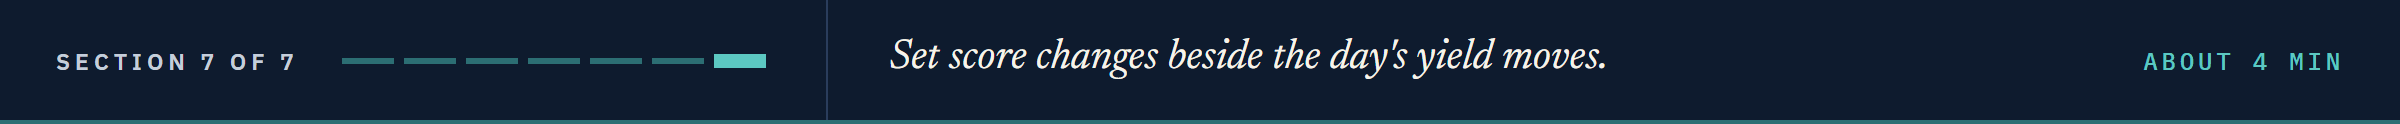

## 18.7 Scores and Yields on Statement Dates

### Yield Changes in Basis Points

Q. Join each score's change from the statement before to that day's 2 Yr and 10 Yr change, in basis points.

In [34]:
# dates as row labels, as in the Treasury case study
yields = pd.read_csv(data_folder + 'treasury_par_yields.csv',
                     parse_dates=['date'], index_col='date')
# percent to basis points; published to 2 decimals, so round(0) clears the float dust
yield_changes = (yields[['2 Yr', '10 Yr']].diff() * 100).round(0)
# Combining Part 2's join() on the shared dates; how='left' keeps every statement
joined = changes.join(yield_changes, how='left')
print(len(joined), len(joined.dropna()))

46 45


45 of 46 rows are complete: only the first statement lacks a change, so every date found its yields.
A missing date would stay `NaN`, never filled from a nearby day.

**Excel side by side.** The yields on a sheet `yields`, dates in A, the 2 Yr in I.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Change in bp</td><td align="left"><code>.diff() * 100</code></td><td align="left"><code>=(I3-I2)*100</code> in P3, filled down</td></tr>
<tr><td align="left">Each statement date's change</td><td align="left"><code>.join(yield_changes, how='left')</code></td><td align="left"><code>=XLOOKUP(A2, yields!$A$2:$A$2941, yields!$P$2:$P$2941)</code>; a missing date gives <code>#N/A</code>, Python's <code>NaN</code></td></tr>
</table>
<br clear="left">

### The Correlations

Q. How does each score change line up with each yield change?

In [35]:
# score changes down the side, yield changes across
correlations = joined.corr().loc[['general', 'vader', 'domain'], ['2 Yr', '10 Yr']]
correlations.style.format('{:.2f}').background_gradient(cmap='Greens', vmin=-1, vmax=1)

,2 Yr,10 Yr
general,0.19,0.07
vader,-0.06,-0.03
domain,0.27,0.16


All six fall between -0.06 and 0.27 on 45 points.
Near zero is a result, and it is reported as one.

Q. Draw the domain change against the 2 Yr change.

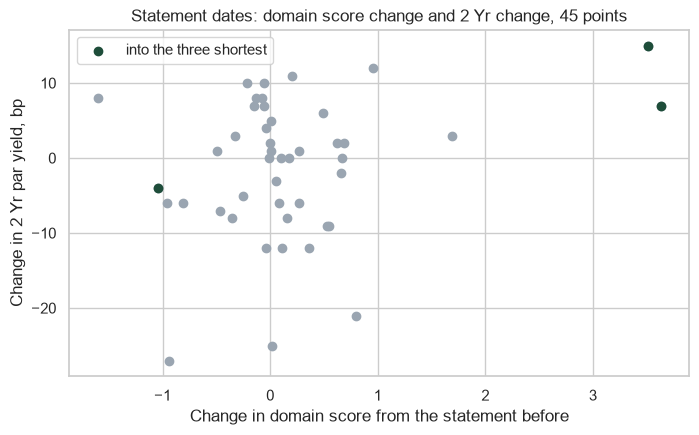

In [36]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# every change in grey, then the changes into the three short statements in the dark green
ax.scatter(joined['domain'], joined['2 Yr'], color='#9AA5B1')
ax.scatter(joined['domain'].iloc[-3:], joined['2 Yr'].iloc[-3:], color='#1E4D3A',
           label='into the three shortest')
ax.legend()
ax.set_title('Statement dates: domain score change and 2 Yr change, 45 points')
ax.set_xlabel('Change in domain score from the statement before')
ax.set_ylabel('Change in 2 Yr par yield, bp')
plt.show()

The cloud has no slope; two points sit far right, the changes into two short statements.

### Without the Three Shortest

Q. What are the same correlations without the last three statements?

In [37]:
# iloc[:-3] leaves out the last three rows
without_last = joined.iloc[:-3]
print(without_last.corr().loc[['general', 'vader', 'domain'], ['2 Yr', '10 Yr']].round(2))

         2 Yr  10 Yr
general -0.07  -0.11
vader   -0.07  -0.04
domain   0.07   0.10


On 42 points all six fall between -0.11 and 0.10: three points carried the 0.27.

<table align="left">
<tr><th align="left">Caution</th><th align="left">Why</th></tr>
<tr><td align="left">Few points</td><td align="left">three left out moved the figure</td></tr>
<tr><td align="left">Other news</td><td align="left">nothing here separates the statement from the rest of the day</td></tr>
<tr><td align="left">A daily yield</td><td align="left">quotes "at or near 3:30 PM each trading day" (https://home.treasury.gov/policy-issues/financing-the-government/interest-rate-statistics/treasury-yield-curve-methodology), not the minutes after a statement</td></tr>
<tr><td align="left">This file only</td><td align="left">a description of 45 pairs, not a cause</td></tr>
</table>
<br clear="left">

**In this file, near zero: -0.06 to 0.27 on 45 points, -0.11 to 0.10 on 42.**

## Summary

The checks behind every answer:

<table align="left">
<tr><th align="left">Check</th><th align="left">Result</th></tr>
<tr><td align="left">File</td><td align="left">46 statements, no gap, no repeat</td></tr>
<tr><td align="left">Tokens</td><td align="left">10,204 kept, Analyzing Text Part 2's count</td></tr>
<tr><td align="left">Join</td><td align="left">45 of 46 rows complete; only the first lacks a change</td></tr>
<tr><td align="left">Changed</td><td align="left">nothing on disk; columns added</td></tr>
</table>
<br clear="left">

A lexicon score is not a meaning, not free of its list, not stable on a short text, and not a measure of anything outside the text.

## You Can Now

By the end of this notebook, you can:

* Score tokens against word lists, and print the words that hit.
* Read the sentences behind a number, with their dates.
* Use VADER on raw text, and list the words it rated.
* Label scores at a stated cut-off, and draw them as percent bars.
* Report a correlation with its number of points.

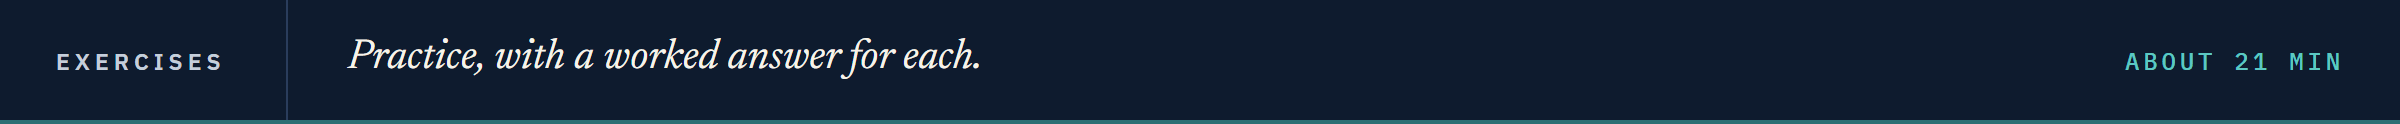

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, which marks your answers, then the statements, lists and functions.

In [38]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [39]:
import os
import re

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer

# the house theme, as in the lesson
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
nltk.download('stopwords', quiet=True)
nltk.download('vader_lexicon', quiet=True)
stop_words = stopwords.words('english')
analyzer = SentimentIntensityAnalyzer()


def clean(text):
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return re.sub(r'\s+', ' ', text).strip().split(' ')


def remove_stop_words(tokens):
    return [token for token in tokens if token not in stop_words]


def list_score(tokens, plus_words, minus_words):
    plus = len([token for token in tokens if token in plus_words])
    minus = len([token for token in tokens if token in minus_words])
    return (plus - minus) / len(tokens) * 100


def vader_score(text):
    return analyzer.polarity_scores(text)['compound']


positive_words = ['good', 'strong', 'better', 'gains', 'support', 'progress', 'improved',
                  'improvement', 'confidence', 'growth', 'solid', 'stable',
                  'recovery', 'benefit']
negative_words = ['bad', 'weak', 'worse', 'risks', 'inflation', 'unemployment', 'pressures',
                  'restrictive', 'uncertain', 'hardship', 'decline', 'loss', 'debt', 'lower']
firm_words = ['expanding', 'expand', 'expanded', 'solid', 'strong', 'robust', 'strengthened',
              'picked', 'resilient', 'gains']
soft_words = ['slowed', 'moderated', 'declined', 'weak', 'weakness', 'weaker', 'softened']

# a fresh copy of the statements; in Colab, from GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
statements['kept'] = statements['text'].apply(clean).apply(remove_stop_words)
statements['n_kept'] = statements['kept'].str.len()
print(statements.shape, statements['n_kept'].sum())

(46, 5) 10204


### Exercise 1

Q. For 2024-03-20, print the hits on each general list. Store the negative count in **ex1_negative** and the score, to 2 decimals, in **ex1_score**.

In [40]:
ex1_negative = ...
ex1_score = ...

In [41]:
check('Exercise 1 negative hits', ex1_negative, 16)
check('Exercise 1 score', ex1_score, -4.95)

Exercise 1 negative hits: not attempted yet
Exercise 1 score: not attempted yet


### Exercise 2

Q. Take `inflation` off the negative list and score all 46 again. Store the number below zero in **ex2_below**, and the lowest statement's date and score, to 2 decimals, in **ex2_date** and **ex2_lowest**.

In [42]:
ex2_below = ...
ex2_date = ...
ex2_lowest = ...

In [43]:
check('Exercise 2 statements below zero', ex2_below, 34)
check('Exercise 2 date of the lowest', ex2_date, '2025-09-17')
check('Exercise 2 lowest score', ex2_lowest, -3.47)

Exercise 2 statements below zero: not attempted yet
Exercise 2 date of the lowest: not attempted yet
Exercise 2 lowest score: not attempted yet


### Exercise 3

Q. Score each statement's **first paragraph** (up to the first `'\n'`) with VADER. Store the number below zero in **ex3_below** and the lowest one's date in **ex3_date**.

In [44]:
ex3_below = ...
ex3_date = ...

In [45]:
check('Exercise 3 first paragraphs below zero', ex3_below, 15)
check('Exercise 3 date of the lowest', ex3_date, '2025-10-29')

Exercise 3 first paragraphs below zero: not attempted yet
Exercise 3 date of the lowest: not attempted yet


### Exercise 4

Q. Store the correlation of `n_kept` with the domain score in **ex4_corr**, and the shortest statement's z-score of `n_kept` in **ex4_z**, both to 2 decimals. Draw one against the other.

In [46]:
ex4_corr = ...
ex4_z = ...

In [47]:
check('Exercise 4 correlation', ex4_corr, -0.75)
check('Exercise 4 z-score of the shortest', ex4_z, -2.57)

Exercise 4 correlation: not attempted yet
Exercise 4 z-score of the shortest: not attempted yet


### Exercise 5

Q. Write `hit_counts(tokens, word_list)`, returning a dict of each listed word found in `tokens` with its count; leave out a word with no hits.

In [48]:
def hit_counts(tokens, word_list):
    """Return a dict: each word of word_list found in tokens, with its count."""
    return ...

In [49]:
# the kept tokens of the statement of 2024-03-20
tokens_0320 = statements.loc[statements['date'] == '2024-03-20', 'kept'].iloc[0]
typed = ['inflation', 'rate', 'inflation', 'gains', 'risks']
check('Exercise 5 typed list', hit_counts(typed, ['inflation', 'risks']),
      {'inflation': 2, 'risks': 1})
check('Exercise 5 negative hits of 2024-03-20', hit_counts(tokens_0320, negative_words),
      {'inflation': 8, 'risks': 4, 'unemployment': 1,
       'uncertain': 1, 'debt': 1, 'pressures': 1})

Exercise 5 typed list: not attempted yet
Exercise 5 negative hits of 2024-03-20: not attempted yet


### Exercise 6

Q. Write `label_score(compound, cutoff)` with no default cut-off. Label every raw-text VADER score at 0.5; store the positive and neutral counts in **ex6_positive** and **ex6_neutral**.

In [50]:
def label_score(compound, cutoff):
    return ...


ex6_positive = ...
ex6_neutral = ...

In [51]:
check('Exercise 6 label of 0.6', label_score(0.6, 0.5), 'positive')
check('Exercise 6 label of -0.5', label_score(-0.5, 0.5), 'negative')
check('Exercise 6 label of 0.2', label_score(0.2, 0.5), 'neutral')
check('Exercise 6 positive statements', ex6_positive, 29)
check('Exercise 6 neutral statements', ex6_neutral, 9)

Exercise 6 label of 0.6: not attempted yet
Exercise 6 label of -0.5: not attempted yet
Exercise 6 label of 0.2: not attempted yet
Exercise 6 positive statements: not attempted yet
Exercise 6 neutral statements: not attempted yet


### Exercise 7: AI check

Q. The lesson found 0.802 for 2025-06-18 and 12 below zero. Run it: does it agree? Fix it so **ex7_score** and **ex7_below** are right.

In [52]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# clean the text first, then score it
statements['cleaned'] = statements['kept'].str.join(' ')
statements['vader'] = statements['cleaned'].apply(vader_score)

ex7_score = round(statements.loc[statements['date'] == '2025-06-18', 'vader'].iloc[0], 4)
ex7_below = int((statements['vader'] < 0).sum())
print(ex7_score, ex7_below)

0.4404 11


In [53]:
check('Exercise 7 score of 2025-06-18', ex7_score, 0.802)
check('Exercise 7 statements below zero', ex7_below, 12)

Exercise 7 score of 2025-06-18: not yet. You have 0.4404
Exercise 7 statements below zero: not yet. You have 11


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">One number, three ways</td><td align="left">42, 12 and 3 of 46 below zero</td></tr>
<tr><td align="left">The words behind them</td><td align="left"><code>inflation</code> is 324 of 838 general hits</td></tr>
<tr><td align="left">Do they agree</td><td align="left">loosely: 0.48, 0.51, 0.21</td></tr>
<tr><td align="left">Against yields</td><td align="left">near zero, on 45 points and on 42</td></tr>
</table>
<br clear="left">

Be proud: you found almost nothing against yields and said so.

Next, From Notebook to Module moves week 3's cleaning routine into a file of functions.

[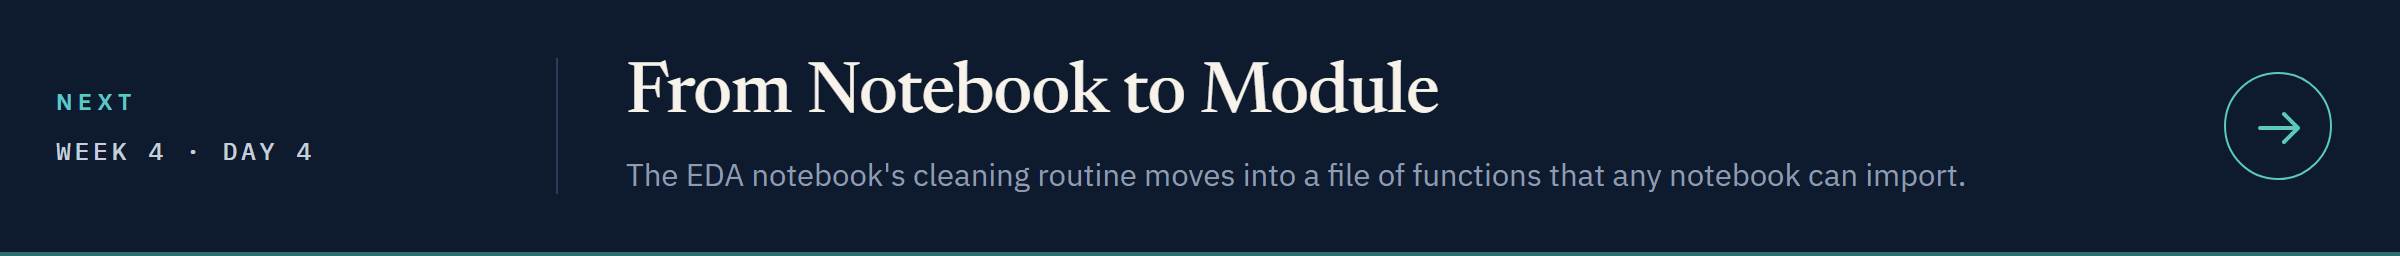](../day4/19_from_notebook_to_module.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day4/19_from_notebook_to_module.ipynb)